# Transatlantic Sail: PDR Calculations (baseline v5)

**CUSail · Sails subsystem · Avram Dreyer · 26 Sep 2026 · PDR Sun 4 Oct**

This notebook calculates the **current baseline** of the transatlantic rigid sail and shows the trade studies that motivate it. It is meant to be read front to back. Every number comes from a numbered equation (listed in Part 2) applied to inputs whose sources are listed in Part 1. The notebook needs nothing outside this folder.

**Baseline:** 8 % circular-arc cambered plate, pivot at 50 % chord, 0.95 m span × 0.65 m chord, mast 1.00 m aft of the bow, self-locking worm drive.

| File in this folder | What it is |
|---|---|
| `README.md` | Reading order and how to run |
| `1_Design_Decisions.md` | Decision log (D0–D9) with the full rationale. Each decision points to the Part of this notebook that supports it. |
| **`2_Calculations.ipynb`** | This notebook: the current baseline and what motivates it. `2_Calculations.html` is the same with outputs. |
| `3_Design_History.ipynb` | Earlier estimates, v0 → v4, re-run with this notebook's method to show how the baseline was reached |
| `data/hull_stations_from_CAD.csv` | Hull section geometry transcribed from the hull CAD (Part 3.1) |
| `data/heeled_buoyancy_curves.csv` | Saved output of Part 3.4 (regenerated if deleted) |

### Structure
| Part | Content |
|---|---|
| 1 | Requirements, constants, inputs and baseline design variables, each with its source |
| 2 | **Equations**: every numbered equation, where it is used and its source |
| 3 | Hull hydrostatics and stability, measured from CAD |
| 4 | Aerodynamic model of the sail section |
| 5 | Baseline calculations: geometry, mass, stability, loads, structure, drive, energy, balance |
| 6 | Why this baseline: section, mast position, what limits size, final size, drive hardware, ballast |
| 7 | **Summary for other subsystems** |
| A–B | References; assumptions register |

### Source tags
Every input carries one of these tags:

| Tag | Meaning |
|---|---|
| **[M]** | Measured from team CAD or team documents |
| **[T]** | Placeholder from another subsystem (will change) |
| **[L#]** | Literature or standard reference (Appendix A) |
| **[D#]** | Design decision (`1_Design_Decisions.md`) |
| **[A]** | Engineering assumption. Listed in Appendix B with how to verify it. |

Equations are numbered **(E#)**.

### Conventions
- SI units. 1 kn = 0.5144 m/s.
- **x** runs aft from the bow plane (hull spans x = 0.05–2.00 m); **y** runs outboard.
- Heights **z** are above the 25 kg design waterline (WL) unless labelled "CAD z".
- Loads are **limit** loads unless marked **ult** (= 1.5 × limit).

In [1]:
import math, os, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

def table(rows, header):
    # Show a list of rows as a formatted table.
    s = "| " + " | ".join(header) + " |\n|" + "---|" * len(header) + "\n"
    s += "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)
    display(Markdown(s))

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

---
# Part 1. Requirements and inputs

## 1.1 Decisions that set the requirements (D0–D5)
Full rationale is in `1_Design_Decisions.md`.

| # | Decision | Effect on the calculations |
|---|---|---|
| D0 | Rigid sail on a rotating mast, driven by a motor + gearbox inside the hull (C-Star / Sailbuoy style) | The drive carries every aerodynamic moment about the mast (5.9) |
| D1 | Rectangular planform, mast on the sail's axis | Simple geometry (5.1) |
| D2 | Rotation ±200° with end stops; no slip ring | End stops share the gearbox static rating (5.9) |
| D3 | Survival holding strategy: self-locking hold for the plate (revised by D6) | Survival torque case (5.9) |
| D4 | Freestanding mast, no side stays | Mast is a cantilever on two bushings (5.6–5.7) |
| D5 | Operate in sea state 5; survive 6+; full power in Bft 2–6; survive 40–50 kn (design to 50 kn) | Load cases (1.3) |

## 1.2 Physical constants

In [2]:
g     = 9.81     # m/s²
rho_a = 1.225    # kg/m³ air, ISA sea level          [L1]
rho_w = 1025.0   # kg/m³ seawater                    [L1]
kn    = 0.5144   # m/s per knot

## 1.3 Environment and load-case winds (D5)
Beaufort ranges are from [L2]. Bft 6 is 22–27 kn, so 27 kn is the top of the full-power range. The survival target of 40–50 kn spans Bft 8 to low Bft 10 on the standard scale, so the design uses the 50 kn upper bound.

In [3]:
V_cruise   = 12.0   # kn, typical trade-wind sailing (Bft 4)              [A]
V_sail_max = 27.0   # kn, top of Bft 6: last full-power / operating case  [D5, L2]
V_survival = 50.0   # kn, survival design wind                            [D5]
SF         = 1.5    # ultimate / limit safety factor                      [A]

## 1.4 Hull, keel and rudder inputs
The hull geometry is read from CAD in Part 3. Keel and rudder are not drawn yet, so their values are placeholders.

In [4]:
M_OTHER    = 15.39   # kg, hull + all systems except rig and ballast     [T] Hull review: 25 kg − 7 kg ballast − 2.61 kg rig (early estimate)
Z_OTHER    = 0.02    # m, CG height of that mass above WL                [A]
shell_t    = 0.003   # m, hull skin thickness                            [A]
bottom_clr = 0.025   # m, heel bushing above inside of hull bottom       [A]
bulb_kg    = 7.0     # kg keel bulb                                      [T] Luis, rough
bulb_depth = 0.28    # m below WL                                        [T] Luis, rough
CLR_x      = 1.15    # m from bow (plausible range 1.12–1.23)            [A] keel not in CAD; the bulb must sit near the LCB for trim
CLR_depth  = 0.15    # m below WL                                        [A]
rudder = dict(x=2.06, area=0.10*0.17, CL_max=0.8, boat_speed=1.2)   # [T] Megan placeholder; CL_max [L8]; 1.2 m/s ≈ 2.3 kn [A]

## 1.5 Sail construction inputs

In [5]:
foot_gap           = 0.10    # m, sail foot above deck (clears bearing flange, seal cone, small hardware) [A]
mast_top_below_tip = 0.10    # m                                                                        [A]
E_mast      = 100e9   # Pa, axial modulus, roll-wrapped CF tube (typ. 70–135 GPa)      [A]
sigma_allow = 400e6   # Pa, allowable bending stress, CF tube (conservative)          [A]
rho_cf      = 1600    # kg/m³ CFRP                                                     [L7]
hardware_kg = 0.5     # kg hub, tip cap, fasteners                                     [A]

**Baseline plate construction** (D10; designed in 5.3, checked in 5.8): E-glass/epoxy faces on a PVC-foam core.

In [6]:
LAYUP = dict(
    plies=2, fabric=0.200,          # plies per face; kg/m² dry woven E-glass per ply                          [A]
    rho_f=2550, rho_r=1150,         # kg/m³ E-glass fibre [L17]; epoxy [A]
    Vf=0.40,                        # fibre volume fraction, vacuum-bagged wet layup                            [L17]
    E_f=17e9, sigma_f=100e6,        # Pa: face modulus; face design allowable at ultimate (knocked down for wet, fatigue) [A]
    core_t=0.010, core_rho=60.0,    # m; kg/m³ Divinycell H60 class                                             [L12]
    core_G=22e6, core_tau=0.35e6,   # Pa: core shear modulus [L12]; shear allowable = 0.5 × 0.7 MPa strength [L12], [A]
    bond=0.10, paint=0.08,          # kg/m² per face: resin in scored-core kerfs + bond line; UV-stable PU paint  [A]
    edge=0.06,                      # kg/m: sealed edge closeouts (filler + glass wrap), all four edges           [A]
    spine_plies=2, spine_w=0.20,    # extra plies per face over the ±100 mm around the mast                       [A]
    fillet=0.010, fillet_rho=700,   # m fillet leg (4 fillets along the mast); kg/m³ thickened epoxy              [A]
    mast_bond=0.05)                 # kg/m adhesive between mast and plate                                        [A]
W_MAX      = 0.005   # m, max panel deflection at limit load (keeps the section shape)            [A]
k_rib_foil = 0.25    # foil only: internal ribs as a fraction of shell mass                         [A]

**Non-composite constructions** compared in 6.7 (sheet on aluminium ribs):

In [7]:
SHEET = {   # E, ν, density; allowables at ultimate / limit (yield) / operating (fatigue, seawater); stock gauges (mm) and minimum practical gauge
 "Al 5052-H32 sheet": dict(E=70.3e9, nu=0.33, rho=2680, ult=228e6, yld=193e6, fat=55e6,          # [L16]; fatigue 117 MPa at 5e8 in air, ~halved for seawater [A]
                           gauges=[0.5, 0.8, 1.0, 1.27, 1.6, 2.0, 2.5, 3.0], t_min=1.0, coldbend=False, paint=0.08),   # pre-rolled to the arc
 "Polycarbonate sheet": dict(E=2.35e9, nu=0.37, rho=1200, ult=20e6, yld=20e6, fat=10e6,          # [A] UV-stabilised; long-term stress ~1/3 of ~60 MPa yield (creep)
                           gauges=[1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0], t_min=2.0, coldbend=True, paint=0.0),        # cold-bent onto the ribs
 "Al composite panel (ACM)": dict(E=70e9, nu=0.33, rho=2700, ult=120e6, yld=100e6, fat=40e6,     # 0.3 mm Al skins on PE core (Dibond type) [A]
                           acm=dict(t_f=0.0003, rho_core=920), gauges=[3.0, 4.0], t_min=3.0, coldbend=False, paint=0.0),
}
RIB = dict(E=68.9e9, rho=2700, ult=290e6, yld=241e6, fat=50e6,   # 6061-T6 flat bar (tube/bar minimums); fatigue ~half of 96 MPa in air [A]
           b=0.004, taper=0.6,                                     # 4 mm thick; tapered rib ≈ 60 % of a prismatic one [A]
           hw=0.04 + 2*0.03)                                       # kg per rib station: mast collar + fasteners for two half-ribs [A]
W_SPAN = 1/100       # sheet deflection between ribs ≤ s_r/100 at limit load   [A]

## 1.6 Drive and operations inputs

In [8]:
slew_deg_s    = 18.0   # deg/s (180° in 10 s)                                 [A]
eta_drive     = 0.30   # overall motor × gearbox efficiency when driving       [A]
standby_W     = 0.10   # W, encoder + driver standby                            [A]
trims_per_day = 144    # one 10° trim every 10 min                              [A]
trim_deg      = 10
tacks_per_day = 10     # 180° flips per day                                     [A]
gust_yaw_deg  = 10.0   # deg, yaw/gust misalignment when feathered in survival [A]

## 1.7 Baseline design variables
These are the outputs of the design process. Part 6 shows why each was chosen.

In [9]:
BASE = dict(span=0.95,        # m   [D8]  (6.4)
            chord=0.65,       # m   [D8]  (6.4)
            mast_x=1.00,      # m from bow  [D7]  (6.2)
            bulb_kg=bulb_kg, bulb_depth=bulb_depth)
# Section: 8 % circular-arc plate, pivot 50 % chord  [D6]  (6.1) -> defined in Part 4 as PLATE

---
# Part 2. Equations

Every equation used in this notebook, grouped by topic in the order it appears. Each entry gives the equation's number, what it is, the section where it is derived and applied, and its source. The same number appears next to the equation in that section and in the code comments.

**Symbols.**
- s: span; c: chord; a: pivot position as a fraction of chord; f: sagitta
- A: sail area; AR: aspect ratio
- q: dynamic pressure; C_F, C_L, C_D, C_m: force, lift, drag and moment coefficients
- ∇: displaced volume; Δ: displacement (mass)
- KB, KG, KM: heights of the centre of buoyancy, centre of gravity and metacentre above the WL
- GZ: righting arm; RM: righting moment
- CE: centre of effort; CLR: centre of lateral resistance
- SF: safety factor

### Hull hydrostatics and stability (Part 3)

**E1: Bottom-arc centre (tangent to bilge arc, on centreline)**. Section 3.1; source: geometry.

$$z_c = z_b + t\,(z_{T2}-z_b),\quad t=\frac{-y_b}{y_{T2}-y_b} \tag{E1}$$

**E2: Bottom-arc radius**. Section 3.1; source: geometry.

$$R_{bot} = \sqrt{y_{T2}^2 + (z_{T2}-z_c)^2} \tag{E2}$$

**E3: Polygon area (shoelace)**. Section 3.3; source: geometry.

$$A = \tfrac12\sum_i (y_i z_{i+1} - y_{i+1} z_i) \tag{E3}$$

**E4: Polygon centroid**. Section 3.3; source: geometry.

$$\bar y = \frac{1}{6A}\sum_i (y_i+y_{i+1})(y_i z_{i+1}-y_{i+1}z_i),\quad \bar z \text{ likewise} \tag{E4}$$

**E5: Displaced volume and displacement**. Section 3.3; source: [L8].

$$\nabla = \int A_s\,dx, \qquad \Delta = \rho_w \nabla \tag{E5}$$

**E6: Longitudinal and vertical centre of buoyancy**. Section 3.3; source: [L8].

$$LCB = \frac{\int x A_s\,dx}{\nabla}, \qquad KB = \frac{\int \bar z A_s\,dx}{\nabla} \tag{E6}$$

**E7: Metacentric radius**. Section 3.3; source: [L8].

$$BM = \frac{I_T}{\nabla}, \qquad I_T = \int \frac{B_{wl}^3}{12}\,dx \tag{E7}$$

**E8: Metacentre height**. Section 3.3; source: [L8].

$$KM = KB + BM \tag{E8}$$

**E9: Righting arm at large heel**. Section 3.4; source: [L8].

$$GZ(\phi) = y_G - y_B = -z_G\sin\phi - y_B(\phi) \tag{E9}$$

**E10: Righting moment**. Section 3.4; source: [L8].

$$RM(\phi) = \Delta\,g\,GZ(\phi) \tag{E10}$$

### Aerodynamics (Part 4)

**E11: Dynamic pressure**. Section 4.1; source: —.

$$q = \tfrac12 \rho_a V^2 \tag{E11}$$

**E12: Resultant sail force**. Section 4.1; source: —.

$$F = q\,A\,C_F \tag{E12}$$

**E13: Helmbold lift slope (low AR)**. Section 4.1; source: [L3].

$$a = \frac{2\pi AR}{2+\sqrt{AR^2+4}} \tag{E13}$$

**E14: Zero-lift angle, circular-arc camber**. Section 4.1; source: [L3].

$$\alpha_{L=0} = -2\,f/c \tag{E14}$$

**E15: Quarter-chord moment, circular-arc camber**. Section 4.1; source: [L3].

$$C_{m,c/4} = \tfrac{\pi}{4}(A_2 - A_1) = -\pi\,f/c \tag{E15}$$

**E16: Drag with induced drag**. Section 4.1; source: [L3].

$$C_D = C_{D0} + \frac{C_L^2}{\pi e\,AR} \tag{E16}$$

**E17: Resultant force coefficient**. Section 4.1; source: —.

$$C_F = \sqrt{C_L^2 + C_D^2} \tag{E17}$$

**E18: Centre-of-pressure travel**. Section 4.3; source: [A].

$$x_{cp}/c = x_{cp,s} + (x_{cp,b}-x_{cp,s})\sin\alpha \tag{E18}$$

### Geometry (5.1–5.2)

**E19: Area and aspect ratio**. Section 5.1; source: —.

$$A = s\,c, \qquad AR = s/c \tag{E19}$$

**E20: Arc radius from sagitta**. Section 5.1; source: geometry.

$$f = (f/c)\,c, \qquad R_{arc} = \frac{(c/2)^2 + f^2}{2f} \tag{E20}$$

**E21: Sweep radius**. Section 5.1; source: geometry.

$$R_{sw} = \max(a,\,1-a)\,c \tag{E21}$$

**E22: Sail-area/displacement ratio**. Section 5.1; source: [L8].

$$SA/D = A/\nabla^{2/3} \tag{E22}$$

**E23: Heights above WL**. Section 5.2; source: [A] uniform loading.

$$z_{foot} = z_{deck} + g_{foot},\quad z_{CE} = z_{foot} + s/2,\quad z_{tip} = z_{foot} + s \tag{E23}$$

**E24: Heel-bushing height and bushing spacing**. Section 5.2; source: —.

$$z_{heel} = -T + t_{shell} + c_{bot}, \qquad L_{brg} = z_{deck} - z_{heel} \tag{E24}$$

**E25: Heeling arm and mast lever**. Section 5.2; source: —.

$$h_{heel} = z_{CE} + d_{CLR}, \qquad h_{mast} = z_{CE} - z_{deck} \tag{E25}$$

### Sail construction (5.3, 6.7)

**E26: Laminate areal mass**. Section 5.3; source: [L17].

$$m''_{lam} = n\,w_f\left[1 + \frac{\rho_r}{\rho_f}\,\frac{1-V_f}{V_f}\right] \tag{E26}$$

**E27: Laminate thickness**. Section 5.3; source: [L17].

$$t_{lam} = \frac{n\,w_f}{\rho_f V_f} \tag{E27}$$

**E28: Sail mass, itemised (sandwich)**. Section 5.3; source: [A], [L12].

$$m_{sail} = 2(1.02A)(m''_{lam} + m''_{bond} + m''_{paint}) + \rho_c t_c A + 2(s+c)\,m'_{edge} + s\,m'_{spine} \tag{E28}$$

**E29: Spine mass per metre of span**. Section 5.3; source: [A].

$$m'_{spine} = 2\,n_{sp} b_{sp}\,m''_{ply} + 4\cdot\tfrac12 l_f^2\,\rho_{fill} + m'_{mb} \tag{E29}$$

**E30: Foil shell mass (6.1 only)**. Section 5.3; source: [A].

$$m_{sail} = 2.04\,c\,s\,(m''_{lam} + m''_{paint})(1 + k_{rib}) \tag{E30}$$

**E64: Sheet strip between ribs (fixed at each rib)**. Section 6.7; source: [L9].

$$M_s = \frac{p\,s_r^2}{12},\qquad \sigma_s = \frac{M_s}{S_s} + \sigma_{bend} \tag{E64}$$

**E65: Sheet stiffness and deflection**. Section 6.7; source: [L9].

$$D_s = \frac{E\,t^3}{12(1-\nu^2)},\qquad w_s = \frac{p\,s_r^4}{384\,D_s} \tag{E65}$$

**E66: Cold-bending stress in a sheet bent to the arc**. Section 6.7; source: [L9].

$$\sigma_{bend} = \frac{E\,t}{2R_{arc}} \tag{E66}$$

**E67: Rib: cantilevered flat bar b × h**. Section 6.7; source: [L9].

$$M_r = \frac{p\,s_r L^2}{2},\quad \sigma_r = \frac{6M_r}{b h^2},\quad w_r = \frac{p\,s_r L^4}{8E\,(b h^3/12)} \tag{E67}$$

**E68: Sheet-and-rib sail mass**. Section 6.7; source: [A].

$$m_{sail} = 1.02A\,(m''_{sheet} + 2m''_{paint}) + n_{st}\left(2k_t\,\rho_r\,b\,h\,L + m_{hw}\right) \tag{E68}$$

### Mass (5.3)

**E31: Mast mass**. Section 5.3; source: [L7].

$$m_{mast} = \rho_{cf}\,\tfrac{\pi}{4}(D_o^2 - D_i^2)\,L_{mast} \tag{E31}$$

**E32: Rig CG height**. Section 5.3; source: —.

$$z_{rig} = \frac{\sum m_i z_i}{\sum m_i} \tag{E32}$$

### Stability (5.4)

**E33: Displacement and system CG**. Section 5.4; source: —.

$$\Delta = m_{oth} + m_{rig} + m_{bulb}, \qquad KG = \frac{m_{oth} z_{oth} + m_{rig} z_{rig} - m_{bulb} d_{bulb}}{\Delta} \tag{E33}$$

**E34: Small-angle righting moment (comparison only)**. Section 5.4; source: [L8].

$$GM = KM - KG, \qquad RM \approx \Delta g\,GM \sin\phi \tag{E34}$$

**E35: Full-power wind**. Section 5.4; source: from E10, E12, E25.

$$V_{fp} = \sqrt{\frac{2\,RM_{20}}{\rho_a A\,C_{F,max}\,h_{heel}}} \tag{E35}$$

### Loads (5.5)

**E36: Heeling and mast-root moments**. Section 5.5; source: —.

$$M_{heel} = F\,h_{heel}, \qquad M_{deck} = F\,h_{mast} \tag{E36}$$

**E37: Feathered lift in a gust**. Section 5.5; source: E13.

$$C_L = a\,\alpha_{gust} \tag{E37}$$

**E38: Wave-dunk force (Morison drag term)**. Section 5.5; source: [L10].

$$F_w = \tfrac12 \rho_w V_w^2\,C_D\,(0.2A) \tag{E38}$$

### Structure (5.6–5.8)

**E39: Tube section properties**. Section 5.6; source: [L9].

$$I = \tfrac{\pi}{64}(D_o^4 - D_i^4), \qquad S = \frac{I}{D_o/2} \tag{E39}$$

**E40: Bending stress**. Section 5.6; source: [L9].

$$\sigma = M/S \tag{E40}$$

**E41: Cantilever deflection at the CE**. Section 5.6; source: [L9].

$$\delta = \frac{F\,h_{mast}^3}{3EI} \tag{E41}$$

**E42: Fatigue cycle count**. Section 5.6; source: [L11], [A].

$$N \approx t_{crossing}/T_{wave} \tag{E42}$$

**E43: Bushing reactions**. Section 5.7; source: statics.

$$R_{heel} = M_{deck}/L_{brg}, \qquad R_{deck} = R_{heel} + F \tag{E43}$$

**E44: Design panel pressures (limit, ultimate, operating)**. Section 5.8; source: E11, E12.

$$p_{lim} = q_{50}\,C_{F,broad},\quad p_{ult} = SF\,p_{lim},\quad p_{op} = q_{27}\,C_{F,max} \tag{E44}$$

**E45: Half-chord root moment per unit span**. Section 5.8; source: statics.

$$m' = p\,\frac{(c/2)^2}{2} \tag{E45}$$

**E46: Half-chord root shear per unit span**. Section 5.8; source: statics.

$$v' = p\,(c/2) \tag{E46}$$

**E47: Sandwich bending stiffness per unit width**. Section 5.8; source: [L15].

$$D = \frac{E_f\,t_f\,d^2}{2},\qquad d = t_c + t_f \tag{E47}$$

**E48: Sandwich face stress**. Section 5.8; source: [L15].

$$\sigma_f = \frac{m'}{t_f\,d} \tag{E48}$$

**E49: Core shear stress**. Section 5.8; source: [L15].

$$\tau_c = \frac{v'}{d} \tag{E49}$$

**E50: Cantilever tip deflection (bending + core shear)**. Section 5.8; source: [L15].

$$w = \frac{p\,L^4}{8D} + \frac{p\,L^2}{2\,G_c\,d} \tag{E50}$$

### Drive and energy (5.9–5.10, 6.5)

**E51: Torque about the mast (conservative)**. Section 5.9; source: [A].

$$T = q\,A\,c\,\left(\lvert C_F (x_{cp} - a)\rvert + \lvert C_m \rvert\right) \tag{E51}$$

**E52: Gearbox/end-stop static requirement**. Section 5.9; source: —.

$$T_{static} = SF\cdot T_{hold} \tag{E52}$$

**E53: Slewing electrical power**. Section 5.10; source: —.

$$P_{el} = T_{op}\,\dot\theta / \eta \tag{E53}$$

**E54: Daily actuation energy**. Section 5.10; source: [A] ops profile.

$$E_{day} = \frac{n_{trim}\theta_{trim} + 180^\circ n_{tack}}{\dot\theta} P_{el} + P_{sb}\cdot 86400\,\mathrm{s} \tag{E54}$$

**E61: Worm torque behind a final stage**. Section 6.5; source: conservative.

$$T_{worm} = T_{hold}/i_f \tag{E61}$$

**E62: Mechanical slewing power**. Section 6.5; source: —.

$$P_{mech} = T_{op}\,\omega,\qquad \omega = \pi/t_{180} \tag{E62}$$

**E63: Motor torque**. Section 6.5; source: —.

$$T_{motor} = \frac{T_{op}}{i_{tot}\,\eta} \tag{E63}$$

### Balance (5.11)

**E55: Angle of attack**. Section 5.11; source: geometry.

$$\alpha = \arccos\lvert \hat e\cdot\hat u\rvert \tag{E55}$$

**E56: Sail force vector**. Section 5.11; source: E11.

$$\vec F = qA\,(C_L \hat L + C_D \hat u) \tag{E56}$$

**E57: Yaw moment about the CLR**. Section 5.11; source: statics.

$$M_z = (x_{CE} - x_{CLR})F_y - y_{CE}F_x \tag{E57}$$

**E58: Rudder moment capacity**. Section 5.11; source: [L8].

$$M_{rud} = \tfrac12\rho_w V_b^2\,A_{rud}\,C_{L,max}\,(x_{rud} - x_{CLR}) \tag{E58}$$

### Trade studies (6.3–6.4)

**E59: Constraint margin (pass if ≥ 1)**. Section 6.3; source: —.

$$\text{margin} = \text{capacity}/\text{demand} \tag{E59}$$

**E60: Torque scaling with size**. Section 6.4; source: from E51, E19.

$$T \propto A\,c = A^{3/2}/\sqrt{AR} \tag{E60}$$

---
# Part 3. Hull hydrostatics and stability, from CAD

## 3.1 Where the hull data comes from
The only hull geometry is `Transatlantic Hull Shell.SLDPRT` (Box/26-27, last saved 9/14; the Master Assembly contains only this part). It is lofted through 14 cross-section sketches. Each sketch has the same four pieces, so the ten numbers per station in `data/hull_stations_from_CAD.csv` describe it fully:

1. a **flat deck** from the centreline out to the **sheer point**
2. a straight **side line** from the sheer point to tangent point **T1** (slight tumblehome)
3. a **bilge arc** from T1 to T2, with a given centre and radius (75 mm amidships)
4. a **bottom arc** from T2 to the keel on the centreline

The bottom arc is tangent to the bilge arc at T2. A tangent arc's centre lies on the line through the bilge centre and T2, and it also lies on the centreline (the section is symmetric). Those two conditions give:


$$z_c = z_b + t\,(z_{T2}-z_b),\quad t=\frac{-y_b}{y_{T2}-y_b} \tag{E1}$$
$$R_{bot} = \sqrt{y_{T2}^2 + (z_{T2}-z_c)^2} \tag{E2}$$



**If the hull CAD changes, re-measure these ten numbers per station and Run All.**

In [10]:
STATIONS = []
with open("../data/hull_stations_from_CAD.csv") as fh:
    for row in csv.DictReader(line for line in fh if not line.startswith("#")):
        STATIONS.append({k: float(v) for k, v in row.items()})
table([[f"{s['x']:.2f}", f"({s['sheer_y']:.3f}, {s['sheer_z']:.3f})", f"({s['T1_y']:.3f}, {s['T1_z']:.3f})",
        f"({s['T2_y']:.3f}, {s['T2_z']:.3f})", f"({s['bilge_cy']:.3f}, {s['bilge_cz']:.3f}), r {s['bilge_r']:.3f}"] for s in STATIONS],
      ["x (m)", "sheer (y, z)", "T1 (y, z)", "T2 (y, z)", "bilge centre, radius"])

| x (m) | sheer (y, z) | T1 (y, z) | T2 (y, z) | bilge centre, radius |
|---|---|---|---|---|
| 0.05 | (0.017, 0.225) | (0.018, 0.002) | (0.016, -0.002) | (0.013, 0.002), r 0.005 |
| 0.10 | (0.036, 0.215) | (0.037, 0.010) | (0.028, -0.007) | (0.017, 0.009), r 0.020 |
| 0.20 | (0.071, 0.200) | (0.075, 0.025) | (0.046, -0.020) | (0.025, 0.025), r 0.050 |
| 0.35 | (0.122, 0.185) | (0.128, 0.038) | (0.090, -0.030) | (0.053, 0.035), r 0.075 |
| 0.50 | (0.169, 0.170) | (0.178, 0.038) | (0.146, -0.029) | (0.103, 0.033), r 0.075 |
| 0.65 | (0.205, 0.158) | (0.216, 0.038) | (0.187, -0.029) | (0.142, 0.031), r 0.075 |
| 0.80 | (0.225, 0.152) | (0.240, 0.040) | (0.211, -0.030) | (0.165, 0.030), r 0.075 |
| 0.95 | (0.228, 0.150) | (0.244, 0.040) | (0.215, -0.030) | (0.170, 0.029), r 0.075 |
| 1.10 | (0.228, 0.150) | (0.244, 0.040) | (0.215, -0.030) | (0.170, 0.029), r 0.075 |
| 1.25 | (0.224, 0.152) | (0.239, 0.040) | (0.211, -0.030) | (0.165, 0.030), r 0.075 |
| 1.40 | (0.216, 0.158) | (0.230, 0.039) | (0.201, -0.029) | (0.156, 0.030), r 0.075 |
| 1.55 | (0.200, 0.165) | (0.211, 0.038) | (0.182, -0.029) | (0.137, 0.031), r 0.075 |
| 1.70 | (0.179, 0.172) | (0.188, 0.037) | (0.156, -0.029) | (0.113, 0.033), r 0.075 |
| 1.85 | (0.163, 0.178) | (0.169, 0.037) | (0.136, -0.028) | (0.093, 0.034), r 0.075 |

## 3.2 Rebuilding each section as a polygon
Each section is drawn as a polygon: 20 points on the bottom arc, 20 on the bilge arc, the sheer point, then mirrored to port. Every section has the same number of points, so the stern face (x = 2.00 m, which has no sketch) can be extrapolated point-by-point from the last two stations.

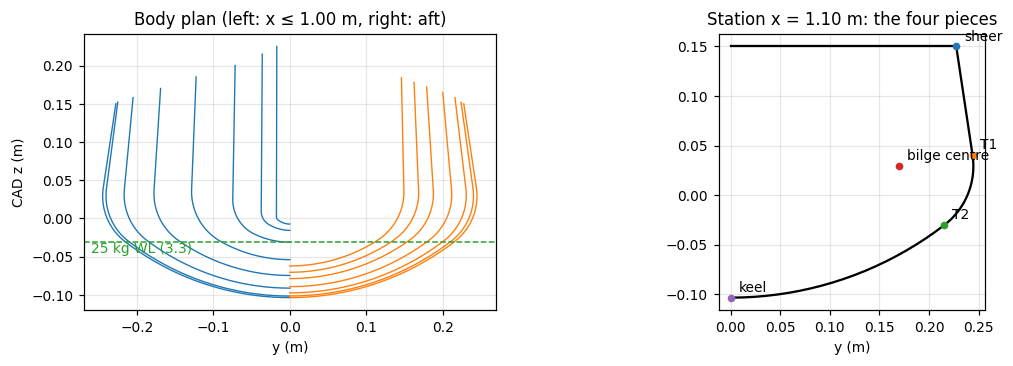

In [11]:
N_ARC = 20

def half_section(s):
    # Starboard half of one station, from the keel (on the centreline) up to the sheer point.
    yb, zb, rb = s["bilge_cy"], s["bilge_cz"], s["bilge_r"]
    y2, z2 = s["T2_y"], s["T2_z"]
    t  = -yb / (y2 - yb)                                              # (E1)
    zc = zb + t * (z2 - zb)
    R  = math.hypot(y2, z2 - zc)                                      # (E2)
    pts = [(0.0, zc - R)]                                             # keel point
    a0, a1 = -math.pi/2, math.atan2(z2 - zc, y2)                      # bottom arc: keel -> T2
    pts += [(R*math.cos(a), zc + R*math.sin(a)) for a in np.linspace(a0, a1, N_ARC+1)[1:]]
    b0, b1 = math.atan2(z2 - zb, y2 - yb), math.atan2(s["T1_z"] - zb, s["T1_y"] - yb)   # bilge arc: T2 -> T1
    pts += [(yb + rb*math.cos(a), zb + rb*math.sin(a)) for a in np.linspace(b0, b1, N_ARC+1)[1:]]
    pts.append((s["sheer_y"], s["sheer_z"]))                          # side line T1 -> sheer
    return np.array(pts)

def full_section(s):
    # Closed polygon: starboard half, then the port half mirrored (the deck closes it).
    h = half_section(s)
    port = h[::-1].copy(); port[:, 0] *= -1
    return np.vstack([h, port[:-1]])           # keel point not repeated

XS    = np.array([s["x"] for s in STATIONS] + [2.00])
POLYS = [full_section(s) for s in STATIONS]
POLYS.append(2*POLYS[-1] - POLYS[-2])          # stern face at x = 2.00 m, linear extrapolation
KEEL_Z = {s["x"]: half_section(s)[0, 1] for s in STATIONS}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1.25, 1]))
for x, P in zip(XS, POLYS):
    side = -1 if x <= 1.00 else 1
    h = P[: len(P)//2 + 1]
    ax[0].plot(side*h[:, 0], h[:, 1], lw=0.9, c="C0" if side < 0 else "C1")
ax[0].axhline(-0.0303, c="C2", ls="--", lw=1); ax[0].text(-0.26, -0.045, "25 kg WL (3.3)", color="C2")
ax[0].set(aspect="equal", title="Body plan (left: x ≤ 1.00 m, right: aft)", xlabel="y (m)", ylabel="CAD z (m)")
s = STATIONS[8]; h = half_section(s)
ax[1].plot(h[:, 0], h[:, 1], c="k"); ax[1].plot([0, s["sheer_y"]], [s["sheer_z"]]*2, c="k")
for lab, (y, z) in {"sheer": (s["sheer_y"], s["sheer_z"]), "T1": (s["T1_y"], s["T1_z"]), "T2": (s["T2_y"], s["T2_z"]),
                    "bilge centre": (s["bilge_cy"], s["bilge_cz"]), "keel": tuple(h[0])}.items():
    ax[1].plot(y, z, "o", ms=4); ax[1].annotate(lab, (y, z), textcoords="offset points", xytext=(5, 4))
ax[1].set(aspect="equal", title=f"Station x = {s['x']:.2f} m: the four pieces", xlabel="y (m)")
plt.tight_layout(); plt.show()

## 3.3 Upright hydrostatics
Each section polygon is clipped at a trial waterline height $h$ (Sutherland–Hodgman half-plane clipping). Its immersed area and centroid come from the shoelace formulas:


$$A = \tfrac12\sum_i (y_i z_{i+1} - y_{i+1} z_i) \tag{E3}$$
$$\bar y = \frac{1}{6A}\sum_i (y_i+y_{i+1})(y_i z_{i+1}-y_{i+1}z_i),\quad \bar z \text{ likewise} \tag{E4}$$


Integrating along x with the trapezoidal rule gives the standard hydrostatic quantities [L8]:


$$\nabla = \int A_s\,dx, \qquad \Delta = \rho_w \nabla \tag{E5}$$
$$LCB = \frac{\int x A_s\,dx}{\nabla}, \qquad KB = \frac{\int \bar z A_s\,dx}{\nabla} \tag{E6}$$
$$BM = \frac{I_T}{\nabla}, \qquad I_T = \int \frac{B_{wl}^3}{12}\,dx \tag{E7}$$
$$KM = KB + BM \tag{E8}$$


$A_s$ is the immersed section area and $B_{wl}$ the waterline beam at each station. The waterline $h$ is found by bisection so that $\rho_w\nabla$ equals the displacement.

In [12]:
def clip_below(P, h):
    # Part of polygon P (rows of y, z) that lies below the horizontal line z = h.
    out = []
    for p, q in zip(P, np.roll(P, -1, axis=0)):
        if p[1] <= h: out.append(p)
        if (p[1] <= h) != (q[1] <= h):
            out.append(p + (h - p[1]) / (q[1] - p[1]) * (q - p))
    return np.array(out)

def area_centroid(P):
    # (E3), (E4): shoelace area and centroid (y, z) of a polygon.
    if len(P) < 3: return 0.0, 0.0, 0.0
    y, z = P[:, 0], P[:, 1]; y1, z1 = np.roll(y, -1), np.roll(z, -1)
    c = y*z1 - y1*z; A = c.sum() / 2
    if abs(A) < 1e-12: return 0.0, 0.0, 0.0
    return abs(A), ((y + y1)*c).sum() / (6*A), ((z + z1)*c).sum() / (6*A)

def trapz(f, x):
    f, x = np.asarray(f, float), np.asarray(x, float)
    return float(np.sum((f[1:] + f[:-1])/2*np.diff(x)))

def immersed(polys, h):
    # (E5), (E6): immersed volume and centre of buoyancy (x, y, z) for sections already rotated to the heel angle.
    a = np.array([area_centroid(clip_below(P, h)) for P in polys])   # columns: area, y-bar, z-bar
    V = trapz(a[:, 0], XS)
    if V == 0: return 0.0, 0.0, 0.0, 0.0
    return (V, trapz(a[:, 0]*XS, XS)/V, trapz(a[:, 0]*a[:, 1], XS)/V, trapz(a[:, 0]*a[:, 2], XS)/V)

def find_waterline(polys, mass):
    # Bisection on the waterline height h so that rho_w * V = mass.
    lo = min(P[:, 1].min() for P in polys); hi = max(P[:, 1].max() for P in polys)
    for _ in range(50):
        h = (lo + hi) / 2
        lo, hi = (h, hi) if rho_w*immersed(polys, h)[0] < mass else (lo, h)
    return (lo + hi) / 2

def waterline_beam(P, h):
    ys = [p[0] + (h - p[1])/(q[1] - p[1])*(q[0] - p[0]) for p, q in zip(P, np.roll(P, -1, axis=0))
          if (p[1] - h)*(q[1] - h) <= 0 and p[1] != q[1]]
    return max(ys) - min(ys) if ys else 0.0

def upright(mass):
    h = find_waterline(POLYS, mass)
    V, LCB, _, zB = immersed(POLYS, h)
    Bwl = np.array([waterline_beam(P, h) for P in POLYS])
    BM  = trapz(Bwl**3/12, XS) / V                                   # (E7)
    return dict(WL_cad=h, V=V, LCB=LCB, KB=zB - h, BM=BM, KM=zB - h + BM,   # (E8)
                Bwl=Bwl.max(), Awp=trapz(Bwl, XS), draft=h - min(KEEL_Z.values()), freeboard=STATIONS[8]["sheer_z"] - h)

In [13]:
H25 = upright(25.0)
WL_CAD, T_canoe, freeboard, KM = H25["WL_cad"], H25["draft"], H25["freeboard"], H25["KM"]
table([["Waterline (CAD z)", f"{WL_CAD:+.4f} m", "sits on the bilge/bottom tangent line: likely the intended design WL"],
       ["Canoe-body draft", f"{T_canoe:.4f} m", "hull review lists 0.0774 m (≈ 27–28 kg)"],
       ["Freeboard, midbody (x 0.95–1.10)", f"{freeboard:.3f} m", "flat deck at CAD z 0.150"],
       ["LCB", f"{H25['LCB']:.3f} m from bow", "the keel bulb must sit near here for trim"],
       ["KB / BM / **KM** (above WL)", f"{H25['KB']:+.3f} / {H25['BM']:.3f} / **{KM:+.3f} m**", ""],
       ["WL beam / waterplane area", f"{H25['Bwl']:.3f} m / {H25['Awp']:.3f} m²", ""],
       ["Immersion", f"{(upright(26.0)['WL_cad'] - WL_CAD)*1000:.1f} mm per kg", ""]],
      ["At 25 kg", "Value", "Note"])
print("Keel-to-deck depth by station (m):", ", ".join(f"{s['x']:.2f}: {s['sheer_z'] - KEEL_Z[s['x']]:.3f}" for s in STATIONS))
print("Max half-beam by station (m):     ", ", ".join(f"{s['x']:.2f}: {s['T1_y']:.3f}" for s in STATIONS))

| At 25 kg | Value | Note |
|---|---|---|
| Waterline (CAD z) | -0.0304 m | sits on the bilge/bottom tangent line: likely the intended design WL |
| Canoe-body draft | 0.0732 m | hull review lists 0.0774 m (≈ 27–28 kg) |
| Freeboard, midbody (x 0.95–1.10) | 0.180 m | flat deck at CAD z 0.150 |
| LCB | 1.131 m from bow | the keel bulb must sit near here for trim |
| KB / BM / **KM** (above WL) | -0.026 / 0.283 / **+0.257 m** |  |
| WL beam / waterplane area | 0.431 m / 0.600 m² |  |
| Immersion | 1.6 mm per kg |  |

Keel-to-deck depth by station (m): 0.05: 0.232, 0.10: 0.231, 0.20: 0.231, 0.35: 0.239, 0.50: 0.245, 0.65: 0.249, 0.80: 0.254, 0.95: 0.254, 1.10: 0.254, 1.25: 0.253, 1.40: 0.255, 1.55: 0.254, 1.70: 0.251, 1.85: 0.248
Max half-beam by station (m):      0.05: 0.018, 0.10: 0.037, 0.20: 0.075, 0.35: 0.128, 0.50: 0.178, 0.65: 0.216, 0.80: 0.240, 0.95: 0.244, 1.10: 0.244, 1.25: 0.239, 1.40: 0.230, 1.55: 0.211, 1.70: 0.188, 1.85: 0.169


**Findings used later:**
- The hull is ~0.25 m deep everywhere aft of x ≈ 0.35 m, so depth does not constrain where the mast goes. What it does fix is the **bushing spacing** (5.2).
- Forward of x ≈ 0.5 m the half-beam drops below ~0.18 m, too narrow to put a motor beside the mast (6.2).

## 3.4 Heeled stability: the righting-arm (GZ) curve
The small-angle formula (E34) overstates the righting moment once the flat deck edge and the bilge start changing the waterplane. So the full curve is computed:

1. Rotate every section polygon by the heel angle φ.
2. Find the waterline that keeps the displaced volume constant (bisection, as in 3.3).
3. Take the lateral centre of buoyancy $y_B(\phi)$ of the immersed shape.
4. The centre of gravity G sits on the centreline at CAD height $z_G$. After rotation its lateral position is $y_G = -z_G\sin\phi$.
5. The righting arm is the lateral distance from G to B, positive when B lies further toward the immersed side than G:


$$GZ(\phi) = y_G - y_B = -z_G\sin\phi - y_B(\phi) \tag{E9}$$
$$RM(\phi) = \Delta\,g\,GZ(\phi) \tag{E10}$$



$y_B(\phi)$ depends only on the hull and the displacement, not on G. It is computed once on a grid of displacements (20–33 kg) and heel angles (0–180°), saved to `data/heeled_buoyancy_curves.csv`, and interpolated afterwards. The deck is treated as watertight, and keel and rudder buoyancy are ignored.

The **angle of vanishing stability (AVS)** is the first angle where GZ crosses zero.

In [14]:
ANGLES = np.arange(0, 181, 2.0)
DISPS  = np.arange(20.0, 33.01, 1.0)
CACHE  = "../data/heeled_buoyancy_curves.csv"

def rotate(P, phi_deg):
    c, s = math.cos(math.radians(phi_deg)), math.sin(math.radians(phi_deg))
    return np.column_stack([P[:, 0]*c - P[:, 1]*s, P[:, 0]*s + P[:, 1]*c])

def yB_curve(mass):
    # Lateral centre of buoyancy vs heel angle, at constant displacement.
    return np.array([immersed(R, find_waterline(R, mass))[2]
                     for R in ([rotate(P, phi) for P in POLYS] for phi in ANGLES)])

if not os.path.exists(CACHE):
    print("Computing heeled buoyancy curves (about a minute)...")
    with open(CACHE, "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["displacement_kg", "heel_deg", "yB_m"])
        for d in DISPS:
            for phi, y in zip(ANGLES, yB_curve(d)): w.writerow([d, phi, f"{y:.6f}"])
_c = np.loadtxt(CACHE, delimiter=",", skiprows=1)
YB = _c[:, 2].reshape(len(DISPS), len(ANGLES))

def yB_at(mass):
    # Linear interpolation of the y_B curve between the tabulated displacements.
    i = int(np.clip(np.searchsorted(DISPS, mass) - 1, 0, len(DISPS) - 2)); f = (mass - DISPS[i]) / (DISPS[i+1] - DISPS[i])
    return YB[i]*(1 - f) + YB[i+1]*f

def gz_curve(mass, KG):
    # (E9). KG = CG height above the 25 kg WL.  Returns GZ (m) at each angle in ANGLES.
    zG_cad = WL_CAD + KG
    return -zG_cad*np.sin(np.radians(ANGLES)) - yB_at(mass)

def avs(gz):
    k = np.where((gz[:-1] > 0) & (gz[1:] <= 0))[0]
    return 180.0 if len(k) == 0 else float(ANGLES[k[0]] + 2*gz[k[0]]/(gz[k[0]] - gz[k[0]+1]))
print("y_B at 25 kg, first few angles:", np.round(yB_at(25.0)[:6], 4))

y_B at 25 kg, first few angles: [ 0.     -0.0079 -0.0157 -0.0232 -0.0305 -0.0374]


---
# Part 4. Aerodynamic model of the sail section

The baseline is an **8 % circular-arc cambered plate pivoted at 50 % chord** (D6). The **NACA 0015 foil pivoted at 20 % chord** is carried alongside, because the section choice is compared in 6.1.

## 4.1 Relations used
**Dynamic pressure and resultant force:**


$$q = \tfrac12 \rho_a V^2 \tag{E11}$$
$$F = q\,A\,C_F \tag{E12}$$


**Finite-wing lift slope**, Helmbold's low-aspect-ratio relation [L3] (straight wings, AR ≲ 4):


$$a = \frac{2\pi AR}{2+\sqrt{AR^2+4}} \tag{E13}$$


**Camber, from thin-airfoil theory** [L3]. For a parabolic camber line $z = 4f\,x(c-x)/c^2$ (≈ circular arc at small camber), the Fourier coefficients are $A_1 = 4f/c$ and $A_2 = 0$, so


$$\alpha_{L=0} = -2\,f/c \tag{E14}$$
$$C_{m,c/4} = \tfrac{\pi}{4}(A_2 - A_1) = -\pi\,f/c \tag{E15}$$


A symmetric foil has $C_{m0} = 0$.

**Induced drag and resultant** (used only for the feathered-in-a-gust case):


$$C_D = C_{D0} + \frac{C_L^2}{\pi e\,AR} \tag{E16}$$
$$C_F = \sqrt{C_L^2 + C_D^2} \tag{E17}$$



In [15]:
def q(V_kn): return 0.5*rho_a*(V_kn*kn)**2                          # (E11)
def helmbold(AR): return 2*math.pi*AR / (2 + math.sqrt(AR**2 + 4))  # (E13)
for v in (8, V_cruise, 20, V_sail_max, V_survival): print(f"q({v:>2.0f} kn) = {q(v):6.1f} Pa")

q( 8 kn) =   10.4 Pa
q(12 kn) =   23.3 Pa
q(20 kn) =   64.8 Pa
q(27 kn) =  118.2 Pa
q(50 kn) =  405.2 Pa


## 4.2 Section coefficients
These are **literature-level estimates, not measurements**. The plate's pitching moment and CP location set the drive torque, which is the binding constraint (6.3). They are the first thing to verify, by CFD or a bench test (Appendix B).

| Symbol | Plate | Foil | Basis |
|---|---|---|---|
| C_F,max: max resultant force | 1.3 | 1.1 | Thin cambered plates keep lift at Re ~10⁵ [L4, L5]. Thick symmetric sections separate early at this Re [L5]. Reduced slightly for AR ≈ 1.5 [A]. |
| C_F,broad: broadside (90°) | 1.35 | 1.2 | Flat plate normal to the flow, AR 1–2: C_D ≈ 1.17–1.2 [L6]. The plate's concave side facing the wind raises it [L6], [A]. |
| C_m0: zero-lift moment about c/4 | −πf/c = −0.25 | 0 | (E15) [L3] |
| x_cp/c at small AoA | 0.30 | 0.25 | Quarter chord [L3], moved aft by the camber couple at operating C_L for the plate [A] |
| x_cp/c when stalled | 0.30 | 0.33 | [A] |
| x_cp/c broadside | 0.50 | 0.45 | Symmetry at 90° [L6]; the foil's round nose shifts it slightly forward [A] |
| C_D0: profile drag | 0.06 | 0.03 | Thin plate vs 15 % foil at Re ~2×10⁵ [L5], [A] |
| Span efficiency e | 0.9 | 0.9 | Rectangular planform [A] |

In [16]:
PLATE = dict(name="8% circular-arc plate", camber=0.08, pivot=0.50,
             CF_max=1.3, CF_broad=1.35, Cm0=-math.pi*0.08, cp_small=0.30, cp_stall=0.30, cp_broad=0.50, CD0=0.06,
             mast_OD=0.042, mast_wall=0.0025, holds=True)       # [D6] baseline. Drive must HOLD in survival (no weathervane) [D3]
FOIL  = dict(name="NACA 0015 foil", t_c=0.15, pivot=0.20,
             CF_max=1.1, CF_broad=1.2, Cm0=0.0, cp_small=0.25, cp_stall=0.33, cp_broad=0.45, CD0=0.03,
             mast_OD=0.040, mast_wall=0.0025, holds=False)      # alternative. Clutch slips and the sail weathervanes
print(f"Plate: Cm0 = {PLATE['Cm0']:.3f} (E15);  zero-lift angle = {math.degrees(-2*PLATE['camber']):.1f}° (E14)")

Plate: Cm0 = -0.251 (E15);  zero-lift angle = -9.2° (E14)


## 4.3 Force coefficients over the full angle range
The balance model (5.11) has to trim the sail at every point of sail, so it needs $C_L(\alpha)$ and $C_D(\alpha)$ from 0 to 90°. The tables below are shaped from the curved-plate and low-AR plate data [L4, L5] and pinned to the end values in 4.2. **[A]: replace with CFD or wind-tunnel data when available.**

The centre of pressure moves from its small-AoA to its broadside position, measured from whichever edge faces the wind:


$$x_{cp}/c = x_{cp,s} + (x_{cp,b}-x_{cp,s})\sin\alpha \tag{E18}$$



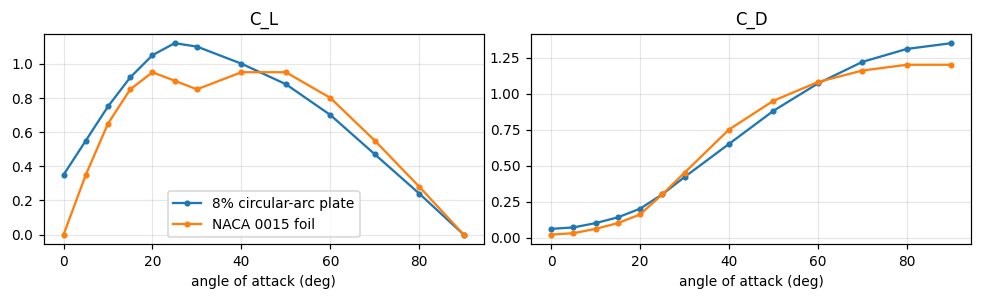

In [17]:
ALPHA    = [0,   5,   10,  15,  20,  25,   30,  40,  50,  60,  70,  80,  90]
PLATE_CL = [.35, .55, .75, .92, 1.05, 1.12, 1.10, 1.00, .88, .70, .47, .24, 0]
PLATE_CD = [.06, .07, .10, .14, .20, .30, .42, .65, .88, 1.07, 1.22, 1.31, 1.35]
FOIL_CL  = [0,   .35, .65, .85, .95, .90, .85, .95, .95, .80, .55, .28, 0]
FOIL_CD  = [.02, .03, .06, .10, .16, .30, .45, .75, .95, 1.08, 1.16, 1.2, 1.2]
PLATE.update(CL=lambda a: np.interp(a, ALPHA, PLATE_CL), CD=lambda a: np.interp(a, ALPHA, PLATE_CD))
FOIL.update(CL=lambda a: np.interp(a, ALPHA, FOIL_CL),  CD=lambda a: np.interp(a, ALPHA, FOIL_CD))
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
for sec_ in (PLATE, FOIL):
    ax[0].plot(ALPHA, [sec_["CL"](a) for a in ALPHA], "o-", ms=3, label=sec_["name"])
    ax[1].plot(ALPHA, [sec_["CD"](a) for a in ALPHA], "o-", ms=3)
ax[0].set(title="C_L", xlabel="angle of attack (deg)"); ax[1].set(title="C_D", xlabel="angle of attack (deg)")
ax[0].legend(); plt.tight_layout(); plt.show()

---
# Part 5. Baseline calculations

Each step is a short function written directly under its equations, then evaluated for the baseline (1.7). Part 6 reuses the same functions to compare alternatives.

In [18]:
sec = PLATE     # [D6]

## 5.1 Planform, section and sweep circle


$$A = s\,c, \qquad AR = s/c \tag{E19}$$
$$f = (f/c)\,c, \qquad R_{arc} = \frac{(c/2)^2 + f^2}{2f} \tag{E20}$$
$$R_{sw} = \max(a,\,1-a)\,c \tag{E21}$$


$R_{arc}$ is the radius of the cylinder or former the plate is laid up on. $a$ is the pivot position as a fraction of chord. The sail-area/displacement ratio compares sail power across boats of different size [L8]:


$$SA/D = A/\nabla^{2/3} \tag{E22}$$



In [19]:
def planform(span, chord, sec):
    A, AR = span*chord, span/chord                                          # (E19)
    out = dict(A=A, AR=AR, R_sweep=max(sec["pivot"], 1 - sec["pivot"])*chord)   # (E21)
    if "camber" in sec:
        f = sec["camber"]*chord; out.update(sagitta=f, R_arc=((chord/2)**2 + f**2)/(2*f))   # (E20)
    return out
P = planform(BASE["span"], BASE["chord"], sec)
table([["Area / aspect ratio", f"{P['A']:.3f} m² / {P['AR']:.2f}"], ["Sagitta / arc radius", f"{P['sagitta']*1000:.0f} mm / {P['R_arc']:.3f} m"],
       ["Sweep circle", f"Ø {2*P['R_sweep']:.2f} m, deck x {BASE['mast_x']-P['R_sweep']:.3f}–{BASE['mast_x']+P['R_sweep']:.3f} m"],
       ["SA/D (E22)", f"{P['A']/(25/rho_w)**(2/3):.1f}"]], ["", "Baseline"])

|  | Baseline |
|---|---|
| Area / aspect ratio | 0.617 m² / 1.46 |
| Sagitta / arc radius | 52 mm / 1.042 m |
| Sweep circle | Ø 0.65 m, deck x 0.675–1.325 m |
| SA/D (E22) | 7.3 |

## 5.2 Heights and lever arms
The CE is at the centroid of the rectangle, i.e. uniform spanwise loading. Real loading drops at the tip, so this slightly overstates heel and mast moment, which is conservative.


$$z_{foot} = z_{deck} + g_{foot},\quad z_{CE} = z_{foot} + s/2,\quad z_{tip} = z_{foot} + s \tag{E23}$$
$$z_{heel} = -T + t_{shell} + c_{bot}, \qquad L_{brg} = z_{deck} - z_{heel} \tag{E24}$$
$$h_{heel} = z_{CE} + d_{CLR}, \qquad h_{mast} = z_{CE} - z_{deck} \tag{E25}$$


The freeboard and draft are the 25 kg values from 3.3. The ±0.5 mm change over the displacements used here is ignored.

In [20]:
def heights(span):
    z = dict(deck=freeboard); z["foot"] = z["deck"] + foot_gap                                        # (E23)
    z["CE"] = z["foot"] + span/2; z["tip"] = z["foot"] + span; z["mast_top"] = z["tip"] - mast_top_below_tip
    z["heel"] = -T_canoe + shell_t + bottom_clr; z["L_brg"] = z["deck"] - z["heel"]                  # (E24)
    z["h_heel"] = z["CE"] + CLR_depth; z["h_mast"] = z["CE"] - z["deck"]                              # (E25)
    return z
Z = heights(BASE["span"])
table([[k, f"{v:+.3f}"] for k, v in Z.items()], ["Point / lever", "m (above WL)"])

| Point / lever | m (above WL) |
|---|---|
| deck | +0.180 |
| foot | +0.280 |
| CE | +0.755 |
| tip | +1.230 |
| mast_top | +1.130 |
| heel | -0.045 |
| L_brg | +0.226 |
| h_heel | +0.905 |
| h_mast | +0.575 |

## 5.3 Sail construction and rig mass
### Baseline construction (D10)
| Element | Specification |
|---|---|
| Faces | 2 × 200 g/m² plain-weave E-glass per face, epoxy, vacuum-bagged (V_f ≈ 0.40) |
| Core | 10 mm PVC foam, 60 kg/m³ (Divinycell H60 class), scored so it drapes onto the 1.04 m arc (5.1) |
| Edges | All four edges sealed: core routed back and filled with thickened epoxy, then wrapped in glass. Both long edges act as a leading edge on one tack. |
| Spine | The mast passes through the plate. The two plate halves are bonded to it with four thickened-epoxy fillets and 2 extra plies per face wrapped over ±100 mm. |
| Finish | UV-stable two-part polyurethane paint, light colour |
| Tooling | Vacuum-bagged on a 1.04 m-radius former (plywood ribs skinned with thin sheet) |

The panel's structural checks are in 5.8. The comparison with carbon faces and non-composite constructions is in 6.7.

**Laminate.** For $n$ plies of dry fabric weight $w_f$ at fibre volume fraction $V_f$:


$$m''_{lam} = n\,w_f\left[1 + \frac{\rho_r}{\rho_f}\,\frac{1-V_f}{V_f}\right] \tag{E26}$$
$$t_{lam} = \frac{n\,w_f}{\rho_f V_f} \tag{E27}$$


**Sail mass, itemised.** Both faces get the 2 % arc-length allowance; $m''_{bond}$ is the resin taken up by the scored core and bond lines. The spine adds the wrap plies, four fillets of leg $l_f$, and the mast adhesive:


$$m_{sail} = 2(1.02A)(m''_{lam} + m''_{bond} + m''_{paint}) + \rho_c t_c A + 2(s+c)\,m'_{edge} + s\,m'_{spine} \tag{E28}$$
$$m'_{spine} = 2\,n_{sp} b_{sp}\,m''_{ply} + 4\cdot\tfrac12 l_f^2\,\rho_{fill} + m'_{mb} \tag{E29}$$


**Foil** (hollow ribbed shell, used only in 6.1): the same laminate wraps 2.04 × chord, plus internal ribs:


$$m_{sail} = 2.04\,c\,s\,(m''_{lam} + m''_{paint})(1 + k_{rib}) \tag{E30}$$


**Mast** (thin-walled tube from the heel bushing to 0.10 m below the tip):


$$m_{mast} = \rho_{cf}\,\tfrac{\pi}{4}(D_o^2 - D_i^2)\,L_{mast} \tag{E31}$$


**Rig CG,** with the sail at $z_{CE}$, the mast at its mid-length and the hardware 0.1 m above the deck:


$$z_{rig} = \frac{\sum m_i z_i}{\sum m_i} \tag{E32}$$



In [21]:
def laminate(L=LAYUP):
    w = L["plies"]*L["fabric"]
    m = w*(1 + L["rho_r"]/L["rho_f"]*(1 - L["Vf"])/L["Vf"])                     # (E26)
    t = w/(L["rho_f"]*L["Vf"])                                                  # (E27)
    return m, t

def sail_mass_items(span, chord, L=LAYUP):
    A = span*chord; m_lam, _ = laminate(L); m_ply = laminate({**L, "plies": 1})[0]
    spine_per_m = 2*L["spine_plies"]*L["spine_w"]*m_ply + 4*(L["fillet"]**2/2)*L["fillet_rho"] + L["mast_bond"]   # (E29)
    return {"faces": 2*1.02*A*m_lam, "bond lines": 2*1.02*A*L["bond"], "paint": 2*1.02*A*L["paint"],             # (E28)
            "core": L["core_rho"]*L["core_t"]*A, "edge closeouts": L["edge"]*2*(span + chord), "spine": spine_per_m*span}

def sail_mass_sandwich(span, chord, sec=None, L=LAYUP): return sum(sail_mass_items(span, chord, L).values())

def sail_mass_foil_shell(span, chord, sec=None):
    return 2.04*chord*span*(laminate()[0] + LAYUP["paint"])*(1 + k_rib_foil)                                    # (E30)

m_lam, t_lam = laminate()
items = sail_mass_items(BASE["span"], BASE["chord"])
print(f"Laminate per face: {m_lam:.3f} kg/m², {t_lam*1000:.2f} mm thick")
table([[k, f"{v:.3f}"] for k, v in items.items()] + [["**Sail (plate + spine)**", f"**{sum(items.values()):.2f}**"]], ["Item", "kg"])
A_ = BASE["span"]*BASE["chord"]
print(f"The allowance used through v5 (0.6 kg/m² per face + 15 %, plus core) gave {0.60*2*1.02*A_*1.15 + 60*0.010*A_:.2f} kg "
      f"(3_Design_History.ipynb). It left out the bond lines, paint, edge closeouts and most of the spine.")

Laminate per face: 0.671 kg/m², 0.39 mm thick


| Item | kg |
|---|---|
| faces | 0.845 |
| bond lines | 0.126 |
| paint | 0.101 |
| core | 0.370 |
| edge closeouts | 0.192 |
| spine | 0.435 |
| **Sail (plate + spine)** | **2.07** |

The allowance used through v5 (0.6 kg/m² per face + 15 %, plus core) gave 1.24 kg (3_Design_History.ipynb). It left out the bond lines, paint, edge closeouts and most of the spine.


In [22]:
def rig_mass(span, chord, sec, Z, build=None):
    build = build or (sail_mass_sandwich if "camber" in sec else sail_mass_foil_shell)
    m_sail = build(span, chord, sec)
    L_mast = Z["mast_top"] - Z["heel"]; OD = sec["mast_OD"]; ID = OD - 2*sec["mast_wall"]
    m_mast = rho_cf*math.pi/4*(OD**2 - ID**2)*L_mast                                           # (E31)
    m = m_sail + m_mast + hardware_kg
    z = (m_sail*Z["CE"] + m_mast*(Z["heel"] + L_mast/2) + hardware_kg*(Z["deck"] + 0.1)) / m   # (E32)
    return dict(m_sail=m_sail, m_mast=m_mast, L_mast=L_mast, m_rig=m, z_rig=z)
Mr = rig_mass(BASE["span"], BASE["chord"], sec, Z)
table([["Sail: plate + spine (above)", f"{Mr['m_sail']:.2f} kg"], [f"Mast CF 42×2.5, L {Mr['L_mast']:.2f} m", f"{Mr['m_mast']:.2f} kg"],
       ["Hub, tip cap, fasteners", f"{hardware_kg:.2f} kg"], ["**Total rotating mass / CG**", f"**{Mr['m_rig']:.2f} kg @ {Mr['z_rig']:+.2f} m**"]], ["Item", "Baseline"])

| Item | Baseline |
|---|---|
| Sail: plate + spine (above) | 2.07 kg |
| Mast CF 42×2.5, L 1.18 m | 0.58 kg |
| Hub, tip cap, fasteners | 0.50 kg |
| **Total rotating mass / CG** | **3.15 kg @ +0.64 m** |

## 5.4 Stability and the full-power wind
The heel requirement is written as a wind speed: the **full-power wind** is the wind at which the sail's maximum force heels the boat to 20°. Above it the sail must be eased or feathered.

Every mass except the rig and ballast is lumped into $m_{oth}$:


$$\Delta = m_{oth} + m_{rig} + m_{bulb}, \qquad KG = \frac{m_{oth} z_{oth} + m_{rig} z_{rig} - m_{bulb} d_{bulb}}{\Delta} \tag{E33}$$


The small-angle estimate is shown for comparison only:


$$GM = KM - KG, \qquad RM \approx \Delta g\,GM \sin\phi \tag{E34}$$


**Used in the design:** $RM_{20}$ from the GZ curve (E9, E10). Setting the upright heeling moment $q\,A\,C_{F,max}\,h_{heel}$ equal to it gives


$$V_{fp} = \sqrt{\frac{2\,RM_{20}}{\rho_a A\,C_{F,max}\,h_{heel}}} \tag{E35}$$


The heeling moment's cos²φ reduction at 20° (−12 %) is ignored, which is conservative.

|  | Baseline, 7 kg @ 0.28 m |
|---|---|
| Displacement | 25.54 kg |
| KG / GM | +0.014 / 0.243 m |
| RM(20°), small-angle (E34) | 20.8 N·m → full power to 13.3 kn |
| **RM(20°), GZ curve (E10), used** | **17.7 N·m → full power to 12.3 kn** |
| AVS | 124° |

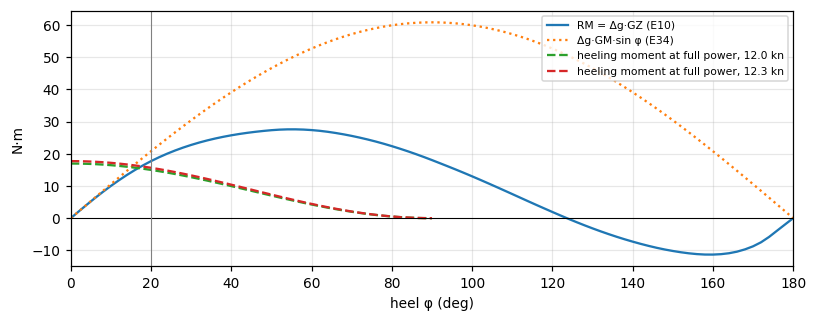

In [23]:
def stability(Mr, bulb_kg, bulb_depth, A, sec, Z):
    disp = M_OTHER + Mr["m_rig"] + bulb_kg                                                    # (E33)
    KG   = (M_OTHER*Z_OTHER + Mr["m_rig"]*Mr["z_rig"] - bulb_kg*bulb_depth) / disp
    gz   = gz_curve(disp, KG)                                                                 # (E9)
    RM20 = disp*g*np.interp(20, ANGLES, gz)                                                   # (E10)
    RM20_gm = disp*g*(KM - KG)*math.sin(math.radians(20))                                     # (E34)
    Vfp  = lambda RM: math.sqrt(2*max(RM, 0)/(rho_a*A*sec["CF_max"]*Z["h_heel"]))/kn          # (E35)
    return dict(disp=disp, KG=KG, GM=KM - KG, gz=gz, RM20=RM20, V_fp=Vfp(RM20), RM20_gm=RM20_gm, V_fp_gm=Vfp(RM20_gm), AVS=avs(gz))
St = stability(Mr, BASE["bulb_kg"], BASE["bulb_depth"], P["A"], sec, Z)
table([["Displacement", f"{St['disp']:.2f} kg"], ["KG / GM", f"{St['KG']:+.3f} / {St['GM']:.3f} m"],
       ["RM(20°), small-angle (E34)", f"{St['RM20_gm']:.1f} N·m → full power to {St['V_fp_gm']:.1f} kn"],
       ["**RM(20°), GZ curve (E10), used**", f"**{St['RM20']:.1f} N·m → full power to {St['V_fp']:.1f} kn**"],
       ["AVS", f"{St['AVS']:.0f}°"]], ["", "Baseline, 7 kg @ 0.28 m"])
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(ANGLES, St["disp"]*g*St["gz"], label="RM = Δg·GZ (E10)")
ax.plot(ANGLES, St["disp"]*g*St["GM"]*np.sin(np.radians(ANGLES)), ":", label="Δg·GM·sin φ (E34)")
ph = ANGLES[ANGLES <= 90]
for v in (V_cruise, St["V_fp"]):
    ax.plot(ph, q(v)*P["A"]*sec["CF_max"]*Z["h_heel"]*np.cos(np.radians(ph))**2, "--", label=f"heeling moment at full power, {v:.1f} kn")
ax.axhline(0, c="k", lw=.7); ax.axvline(20, c="gray", lw=.7)
ax.set(xlabel="heel φ (deg)", ylabel="N·m", xlim=(0, 180)); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 5.5 Load cases
With the force (E12) applied at the CE of an upright boat:


$$M_{heel} = F\,h_{heel}, \qquad M_{deck} = F\,h_{mast} \tag{E36}$$


**Feathered in survival.** The sail points into the wind, but a gust or yaw of 10° gives it an angle of attack. $C_F$ then follows from (E16) and (E17) with


$$C_L = a\,\alpha_{gust} \tag{E37}$$


**Broadside in survival** is a real case for the plate, not just a check. A cambered plate on a mid-chord pivot has no stable weathervane position, so with the drive disengaged it rests roughly broadside (D6).

**Wave dunk.** A breaking crest submerges the top 20 % of the sail at 1.5 m/s orbital velocity, with $C_D$ = 1.2 [A], acting 0.12 m below the tip:


$$F_w = \tfrac12 \rho_w V_w^2\,C_D\,(0.2A) \tag{E38}$$


The **design mast-root moment** is the larger of the 50 kn broadside and wave-dunk moments.

In [24]:
def feathered_CF(AR, sec):
    CL = helmbold(AR)*math.radians(gust_yaw_deg)                                  # (E37)
    return math.hypot(CL, sec["CD0"] + CL**2/(math.pi*0.9*AR))                    # (E16), (E17)

def loads(A, AR, sec, Z):
    CFf = feathered_CF(AR, sec)
    cases = [("Cruise 8 kn, full power", 8, sec["CF_max"]), ("Cruise 12 kn, full power", 12, sec["CF_max"]),
             ("20 kn, full power (upper bound)", 20, sec["CF_max"]), ("27 kn, full power (upper bound)", 27, sec["CF_max"]),
             ("27 kn, broadside", 27, sec["CF_broad"]), (f"50 kn, feathered, ±{gust_yaw_deg:.0f}° gust", 50, CFf),
             ("50 kn, broadside (design case)", 50, sec["CF_broad"])]
    rows = [(n, q(v), cf, q(v)*A*cf) for n, v, cf in cases]                       # (E12)
    F_s = q(V_survival)*A*sec["CF_broad"]
    F_w = 0.5*rho_w*1.5**2*1.2*0.2*A; arm_w = Z["tip"] - 0.12 - Z["deck"]           # (E38)
    M_lim = max(F_s*Z["h_mast"], F_w*arm_w)                                       # (E36)
    return dict(rows=rows, F_s=F_s, F_w=F_w, M_w=F_w*arm_w, M_lim=M_lim, M_ult=SF*M_lim, CF_feath=CFf)
Ld = loads(P["A"], P["AR"], sec, Z)
table([[n, f"{qq:.0f}", f"{cf:.2f}", f"{F:.0f}", f"{F*Z['h_heel']:.0f}", f"{F*Z['h_mast']:.0f}"] for n, qq, cf, F in Ld["rows"]] +
      [["Wave dunk, top 20 % at 1.5 m/s", "—", "1.2", f"{Ld['F_w']:.0f}", "—", f"{Ld['M_w']:.0f}"]],
      ["Case", "q (Pa)", "C_F", "F (N)", "M_heel (N·m)", "M_deck (N·m)"])
print(f"Design mast-root moment: {Ld['M_lim']:.0f} N·m limit / {Ld['M_ult']:.0f} N·m ultimate; shear {Ld['F_s']:.0f} N")
print(f"Check: a breaking crest at 3 m/s gives {0.5*rho_w*3**2*1.2*0.2*P['A']*(Z['tip']-0.12-Z['deck']):.0f} N·m. That exceeds the design, so it is left to weather routing (D5).")

| Case | q (Pa) | C_F | F (N) | M_heel (N·m) | M_deck (N·m) |
|---|---|---|---|---|---|
| Cruise 8 kn, full power | 10 | 1.30 | 8 | 8 | 5 |
| Cruise 12 kn, full power | 23 | 1.30 | 19 | 17 | 11 |
| 20 kn, full power (upper bound) | 65 | 1.30 | 52 | 47 | 30 |
| 27 kn, full power (upper bound) | 118 | 1.30 | 95 | 86 | 55 |
| 27 kn, broadside | 118 | 1.35 | 98 | 89 | 57 |
| 50 kn, feathered, ±10° gust | 405 | 0.37 | 92 | 84 | 53 |
| 50 kn, broadside (design case) | 405 | 1.35 | 338 | 306 | 194 |
| Wave dunk, top 20 % at 1.5 m/s | — | 1.2 | 171 | — | 159 |

Design mast-root moment: 194 N·m limit / 291 N·m ultimate; shear 338 N
Check: a breaking crest at 3 m/s gives 636 N·m. That exceeds the design, so it is left to weather routing (D5).


## 5.6 Mast tube
Thin-walled circular tube, cantilevered from the deck bushing [L9]:


$$I = \tfrac{\pi}{64}(D_o^4 - D_i^4), \qquad S = \frac{I}{D_o/2} \tag{E39}$$
$$\sigma = M/S \tag{E40}$$
$$\delta = \frac{F\,h_{mast}^3}{3EI} \tag{E41}$$


Fatigue cycle count: the crossing takes 127 days (the C-Star PC13 MicroTransat crossing, 2026 [L11]) and T ≈ 7 s is a typical trade-wind sea period [A]:


$$N \approx t_{crossing}/T_{wave} \tag{E42}$$



In [25]:
def mast_check(sec, M_ult, F, h_mast):
    OD = sec["mast_OD"]; ID = OD - 2*sec["mast_wall"]
    I = math.pi/64*(OD**4 - ID**4); S = I/(OD/2)                                   # (E39)
    return dict(I=I, S=S, sigma_ult=M_ult/S, defl=F*h_mast**3/(3*E_mast*I))       # (E40), (E41)
Mc = mast_check(sec, Ld["M_ult"], Ld["F_s"], Z["h_mast"])
print(f"I = {Mc['I']:.3e} m⁴,  S = {Mc['S']*1e6:.2f} cm³")
print(f"σ_ult = {Mc['sigma_ult']/1e6:.0f} MPa vs {sigma_allow/1e6:.0f} MPa allowable → margin {sigma_allow/Mc['sigma_ult']:.1f}×;  CE deflection (limit) {Mc['defl']*1000:.1f} mm")
print(f"Fatigue (E42): ≈ {127*86400/7/1e6:.1f} million wave cycles per crossing")
for OD in (0.030, 0.035, 0.038, 0.042):
    print(f"   OD {OD*1000:.0f} × 2.5 mm: σ_ult = {mast_check(dict(mast_OD=OD, mast_wall=0.0025), Ld['M_ult'], 0, 1)['sigma_ult']/1e6:.0f} MPa")

I = 6.075e-08 m⁴,  S = 2.89 cm³
σ_ult = 101 MPa vs 400 MPa allowable → margin 4.0×;  CE deflection (limit) 3.5 mm
Fatigue (E42): ≈ 1.6 million wave cycles per crossing
   OD 30 × 2.5 mm: σ_ult = 212 MPa
   OD 35 × 2.5 mm: σ_ult = 150 MPa
   OD 38 × 2.5 mm: σ_ult = 125 MPa
   OD 42 × 2.5 mm: σ_ult = 101 MPa


## 5.7 Bushing reactions
The mast is a beam on two supports (deck and heel bushings) with an overhanging load. Taking moments about the deck bushing:


$$R_{heel} = M_{deck}/L_{brg}, \qquad R_{deck} = R_{heel} + F \tag{E43}$$


Axial slam load: $3g\cdot m_{rig}$ down [A].

In [26]:
def bearings(M, F, L): return M/L, M/L + F                                         # (E43)
rows = []
for L in (0.15, Z["L_brg"], 0.30):
    Rh, Rd = bearings(Ld["M_lim"], Ld["F_s"], L)
    rows.append([f"{L:.3f}" + (" (hull depth, baseline)" if L == Z["L_brg"] else ""), f"{Rh:.0f} / {Rh*SF:.0f}", f"{Rd:.0f} / {Rd*SF:.0f}"])
table(rows, ["Bushing spacing (m)", "Heel, limit / ult (N)", "Deck, limit / ult (N)"])
print(f"Axial slam (3 g): {3*g*Mr['m_rig']:.0f} N down.  0.30 m spacing needs a ~75 mm raised deck boss.")

| Bushing spacing (m) | Heel, limit / ult (N) | Deck, limit / ult (N) |
|---|---|---|
| 0.150 | 1295 / 1942 | 1633 / 2449 |
| 0.226 (hull depth, baseline) | 861 / 1292 | 1199 / 1798 |
| 0.300 | 647 / 971 | 985 / 1478 |

Axial slam (3 g): 93 N down.  0.30 m spacing needs a ~75 mm raised deck boss.


## 5.8 Plate structure: sandwich panel and spine
**Design pressures** over the whole sail: limit is 50 kn broadside, and operating is 27 kn at full power (applied every wave, for fatigue):


$$p_{lim} = q_{50}\,C_{F,broad},\quad p_{ult} = SF\,p_{lim},\quad p_{op} = q_{27}\,C_{F,max} \tag{E44}$$


Each half-chord cantilevers off the spine over $L = c/2$. This is conservative, because the fillets shorten the free length slightly. Per metre of span, the root moment and shear are


$$m' = p\,\frac{(c/2)^2}{2} \tag{E45}$$
$$v' = p\,(c/2) \tag{E46}$$


**Sandwich with thin faces** (the faces carry bending, the core carries shear) [L15]:


$$D = \frac{E_f\,t_f\,d^2}{2},\qquad d = t_c + t_f \tag{E47}$$
$$\sigma_f = \frac{m'}{t_f\,d} \tag{E48}$$
$$\tau_c = \frac{v'}{d} \tag{E49}$$
$$w = \frac{p\,L^4}{8D} + \frac{p\,L^2}{2\,G_c\,d} \tag{E50}$$


The checks are:
- face stress at ultimate ≤ the face allowable
- core shear at ultimate ≤ the core allowable
- tip deflection at limit ≤ W_MAX

At the root, the faces and the wrap plies carry the same moment $m'$ into the spine, so the face check covers the spine laminate too.

In [27]:
p_lim = q(V_survival)*sec["CF_broad"]; p_ult = SF*p_lim; p_op = q(V_sail_max)*sec["CF_max"]       # (E44)
L_h = BASE["chord"]/2

def sandwich_check(Lay, L=L_h):
    _, t_f = laminate(Lay); d = Lay["core_t"] + t_f
    D = Lay["E_f"]*t_f*d**2/2                                                              # (E47)
    m_root, v_root = p_ult*L**2/2, p_ult*L                                                 # (E45), (E46)
    sigma, tau = m_root/(t_f*d), v_root/d                                                  # (E48), (E49)
    w = p_lim*L**4/(8*D) + p_lim*L**2/(2*Lay["core_G"]*d)                                  # (E50)
    return dict(t_f=t_f, d=d, D=D, m_root=m_root, v_root=v_root, sigma=sigma, tau=tau, w=w)

Sw = sandwich_check(LAYUP)
print(f"p_lim = {p_lim:.0f} Pa, p_ult = {p_ult:.0f} Pa, p_op = {p_op:.0f} Pa")
table([["Face thickness t_f / lever d", f"{Sw['t_f']*1000:.2f} / {Sw['d']*1000:.1f} mm", ""],
       ["Bending stiffness D", f"{Sw['D']:.0f} N·m", ""],
       ["Root moment m' / shear v' (ultimate)", f"{Sw['m_root']:.1f} N·m/m / {Sw['v_root']:.0f} N/m", ""],
       ["Face stress (ultimate)", f"{Sw['sigma']/1e6:.1f} MPa", f"allowable {LAYUP['sigma_f']/1e6:.0f} MPa → margin {LAYUP['sigma_f']/Sw['sigma']:.0f}×"],
       ["Core shear (ultimate)", f"{Sw['tau']/1e3:.0f} kPa", f"allowable {LAYUP['core_tau']/1e3:.0f} kPa → margin {LAYUP['core_tau']/Sw['tau']:.0f}×"],
       ["Tip deflection (limit)", f"{Sw['w']*1000:.1f} mm", f"limit {W_MAX*1000:.0f} mm"]], ["Check", "Value", "Result"])
for tc in np.arange(0.003, 0.0131, 0.001):
    if sandwich_check({**LAYUP, "core_t": tc})["w"] <= W_MAX:
        print(f"Thinnest core meeting the {W_MAX*1000:.0f} mm deflection limit: {tc*1000:.0f} mm (baseline 10 mm keeps margin for the curvature-free assumption and handling)"); break
print("Strength margins are large: the 2-ply faces are set by damage tolerance (impact, handling, abrasion) rather than by stress [A].")

p_lim = 547 Pa, p_ult = 820 Pa, p_op = 154 Pa


| Check | Value | Result |
|---|---|---|
| Face thickness t_f / lever d | 0.39 / 10.4 mm |  |
| Bending stiffness D | 360 N·m |  |
| Root moment m' / shear v' (ultimate) | 43.3 N·m/m / 267 N/m |  |
| Face stress (ultimate) | 10.6 MPa | allowable 100 MPa → margin 9× |
| Core shear (ultimate) | 26 kPa | allowable 350 kPa → margin 14× |
| Tip deflection (limit) | 2.2 mm | limit 5 mm |

Thinnest core meeting the 5 mm deflection limit: 7 mm (baseline 10 mm keeps margin for the curvature-free assumption and handling)
Strength margins are large: the 2-ply faces are set by damage tolerance (impact, handling, abrasion) rather than by stress [A].


## 5.9 Drive torque about the mast
The torque is the resultant force times its offset from the pivot, plus the camber couple:


$$T = q\,A\,c\,\left(\lvert C_F (x_{cp} - a)\rvert + \lvert C_m \rvert\right) \tag{E51}$$


The two terms are added as **magnitudes**. In reality they partly cancel, so this is a conservative upper bound until the moment curve is measured (Appendix B).

**Cases:**
- **Operating** (27 kn, the top of the full-power range): trimmed ($C_F$ = 0.35, full $C_m$) or stalled ($C_{F,max}$, half $C_m$). Add a motion term for 1 g of roll acting on the sail's CG offset from the axis: 20 mm for the plate (from camber) or (0.45 − a)c for the foil.
- **Plate survival hold:** 50 kn with the drive locked and the sail forced to 20–40° AoA by gusts or yaw. Take the larger of the feathered and mid-AoA values. Gearbox and end stops are rated to


$$T_{static} = SF\cdot T_{hold} \tag{E52}$$


- **Foil (6.1 only):** a slip clutch set at 1.2 × max(broadside at 27 kn, operating) lets the sail weathervane. Gearbox static = 2 × clutch.

In [28]:
def drive(A, AR, chord, sec, m_sail):
    a, Cm = sec["pivot"], abs(sec["Cm0"])
    T = lambda v, CF, cp, cm=0.0: q(v)*A*chord*(abs(CF*(cp - a)) + abs(cm))          # (E51)
    d = dict(trim=T(27, 0.35, sec["cp_small"], Cm), stall=T(27, sec["CF_max"], sec["cp_stall"], 0.5*Cm),
             broad27=T(27, sec["CF_broad"], sec["cp_broad"]),
             feath=T(50, feathered_CF(AR, sec), sec["cp_small"], Cm), mid=T(50, sec["CF_max"], sec["cp_stall"], 0.5*Cm))
    cg_off = 0.02 if "camber" in sec else (0.45 - a)*chord
    d["motion"] = m_sail*g*1.0*cg_off
    d["op"] = max(d["trim"], d["stall"]) + d["motion"]
    if sec["holds"]: d["hold"] = max(d["feath"], d["mid"]); d["static"] = SF*d["hold"]    # (E52)
    else:            d["hold"] = 1.2*max(d["broad27"], d["op"]); d["static"] = 2*d["hold"]
    return d
Dr = drive(P["A"], P["AR"], BASE["chord"], sec, Mr["m_sail"])
table([["27 kn trimmed / stalled", f"{Dr['trim']:.1f} / {Dr['stall']:.1f}"], ["Motion term", f"{Dr['motion']:.2f}"],
       ["**Operating**", f"**{Dr['op']:.0f}**"], ["50 kn feathered ±10° / forced to mid-AoA", f"{Dr['feath']:.0f} / {Dr['mid']:.0f}"],
       ["**Survival hold (no slip)**", f"**{Dr['hold']:.0f}**"], ["**Gearbox + end stops, static (E52)**", f"**{Dr['static']:.0f}**"]], ["Baseline", "N·m"])

| Baseline | N·m |
|---|---|
| 27 kn trimmed / stalled | 15.2 / 18.3 |
| Motion term | 0.41 |
| **Operating** | **19** |
| 50 kn feathered ±10° / forced to mid-AoA | 53 / 63 |
| **Survival hold (no slip)** | **63** |
| **Gearbox + end stops, static (E52)** | **94** |

## 5.10 Actuation energy


$$P_{el} = T_{op}\,\dot\theta / \eta \tag{E53}$$
$$E_{day} = \frac{n_{trim}\theta_{trim} + 180^\circ n_{tack}}{\dot\theta} P_{el} + P_{sb}\cdot 86400\,\mathrm{s} \tag{E54}$$



In [29]:
def energy_Wh(T_op):
    P_el = T_op*math.radians(slew_deg_s)/eta_drive                                   # (E53)
    t_move = (trims_per_day*trim_deg + tacks_per_day*180)/slew_deg_s
    return dict(P_el=P_el, t_move=t_move, E=(t_move*P_el + standby_W*86400)/3600)    # (E54)
En = energy_Wh(Dr["op"])
print(f"Slewing power {En['P_el']:.0f} W for {En['t_move']:.0f} s/day → {En['t_move']*En['P_el']/3600:.2f} Wh; standby {standby_W*24:.1f} Wh; total ≈ {En['E']:.1f} Wh/day")

Slewing power 20 W for 180 s/day → 0.98 Wh; standby 2.4 Wh; total ≈ 3.4 Wh/day


## 5.11 Balance: CE vs CLR, and rudder authority
For a sail rotated to angle δ (chord relative to the centreline) in apparent wind from angle β:
- The angle of attack (E55) uses $\hat e$, the chord direction, and $\hat u$, the flow direction.
- The CE lies on the chord at $x_{cp}(\alpha)$ (E18) from the upwind edge.
- The force is lift perpendicular to the flow toward leeward plus drag along the flow (E56).
- The driving force is $-F_x$, and the yaw moment about the CLR is (E57).
- The plate with its concave side to leeward (sail "backwards") gets a heavy lift penalty, as does the foil with its trailing edge upwind. The trim search therefore always finds the correct orientation.

At each apparent-wind angle the sail is trimmed for maximum drive (δ in 1° steps). The rudder's capacity to cancel the yaw moment is (E58).


$$\alpha = \arccos\lvert \hat e\cdot\hat u\rvert \tag{E55}$$
$$\vec F = qA\,(C_L \hat L + C_D \hat u) \tag{E56}$$
$$M_z = (x_{CE} - x_{CLR})F_y - y_{CE}F_x \tag{E57}$$
$$M_{rud} = \tfrac12\rho_w V_b^2\,A_{rud}\,C_{L,max}\,(x_{rud} - x_{CLR}) \tag{E58}$$



In [30]:
def sail_force(delta, awa, aws, mast_x, span, chord, sec):
    d, b = math.radians(delta), math.radians(awa)
    e = np.array([math.cos(d), math.sin(d)]); n = np.array([-math.sin(d), math.cos(d)])
    u = np.array([math.cos(b), -math.sin(b)])                         # flow direction (x aft, y starboard)
    eu, un = e @ u, u @ n
    alpha = math.degrees(math.acos(min(1.0, abs(eu))))               # (E55)
    uA, uB = -sec["pivot"]*chord, (1 - sec["pivot"])*chord            # chord positions of the two edges (A = true LE)
    u_up, u_dn = (uA, uB) if uA*eu < uB*eu else (uB, uA)
    CL, CD = float(sec["CL"](alpha)), float(sec["CD"](alpha))
    if "camber" in sec and not un > 0: CL = 0.55*CL - 0.3*math.cos(math.radians(alpha))   # concave side to leeward
    if "camber" not in sec and u_up != uA: CL *= 0.6; CD *= 1.1                             # foil flying backwards
    x_cp = sec["cp_small"] + (sec["cp_broad"] - sec["cp_small"])*math.sin(math.radians(alpha))   # (E18)
    ce = np.array([mast_x, 0.0]) + (u_up + (u_dn - u_up)*x_cp)*e
    lee = n if un >= 0 else -n
    L = np.array([-u[1], u[0]]); L = L if L @ lee >= 0 else -L
    F = q(aws)*span*chord*(CL*L + CD*u)                               # (E56)
    return dict(ce=ce, F=F, drive=-F[0], Mz=(ce[0] - CLR_x)*F[1] - ce[1]*F[0])   # (E57)

def helm_sweep(mast_x, span, chord, sec, aws=V_cruise):
    # Rows: apparent wind angle, CE − CLR (m), helm moment (N·m, + weather / − lee), at best-drive trim.
    rows = []
    for awa in range(30, 181, 5):
        best = max((sail_force(dd, awa, aws, mast_x, span, chord, sec) for dd in range(-180, 181)), key=lambda r: r["drive"])
        rows.append((awa, best["ce"][0] - CLR_x, -best["Mz"]))
    return np.array(rows)

M_rud = 0.5*rho_w*rudder["boat_speed"]**2*rudder["area"]*rudder["CL_max"]*(rudder["x"] - CLR_x)   # (E58)
HB = helm_sweep(BASE["mast_x"], BASE["span"], BASE["chord"], sec)
lee_B = max(0.0, -HB[HB[:, 0] >= 40, 2].min())
print(f"Rudder capacity (placeholder rudder) = {M_rud:.2f} N·m")
print(f"Baseline at 12 kn: CE − CLR at 45° AWA {HB[HB[:,0]==45,1][0]*1000:+.0f} mm, running {HB[-1,1]*1000:+.0f} mm; "
      f"max lee helm {lee_B:.1f} N·m = {lee_B/M_rud:.0%} of rudder capacity")

Rudder capacity (placeholder rudder) = 9.13 N·m
Baseline at 12 kn: CE − CLR at 45° AWA -228 mm, running -150 mm; max lee helm 3.3 N·m = 36% of rudder capacity


## 5.12 Everything in one call
`size_rig` chains 5.1–5.10 in order, so Part 6 (and the design-history notebook) can compare alternatives. It contains no new physics. The optional `build` argument swaps in a different sail-mass estimate (used in 6.7 and in the history notebook).

In [31]:
def size_rig(span, chord, sec, bulb_kg=bulb_kg, bulb_depth=bulb_depth, build=None):
    P = planform(span, chord, sec); Z = heights(span); Mr = rig_mass(span, chord, sec, Z, build)
    St = stability(Mr, bulb_kg, bulb_depth, P["A"], sec, Z); Ld = loads(P["A"], P["AR"], sec, Z)
    Mc = mast_check(sec, Ld["M_ult"], Ld["F_s"], Z["h_mast"]); Rh, Rd = bearings(Ld["M_lim"], Ld["F_s"], Z["L_brg"])
    Dr = drive(P["A"], P["AR"], chord, sec, Mr["m_sail"]); En = energy_Wh(Dr["op"])
    return dict(span=span, chord=chord, **P, **{"z_" + k: v for k, v in Z.items()}, **Mr, **St, **Ld, **Mc,
                R_heel=Rh, R_deck=Rd, **{"T_" + k: v for k, v in Dr.items()}, E=En["E"])
B = size_rig(BASE["span"], BASE["chord"], PLATE)
print(f"Check against 5.1–5.10: hold {B['T_hold']:.0f} N·m, static {B['T_static']:.0f} N·m, M_deck {B['M_lim']:.0f}/{B['M_ult']:.0f} N·m, full power to {B['V_fp']:.1f} kn")

Check against 5.1–5.10: hold 63 N·m, static 94 N·m, M_deck 194/291 N·m, full power to 12.3 kn


---
# Part 6. Why this baseline

Each subsection below supports one choice in 1.7 by comparing the baseline against its alternatives with the Part 5 method. Earlier estimates that were superseded are in `3_Design_History.ipynb`.

## 6.1 Section: cambered plate vs NACA 0015 foil (D6)
Same planform, heights and hull. The foil is pivoted at 20 % chord, with its CP just aft of the pivot, so it **weathervanes**: a slip clutch can be its survival mode. The plate cannot weathervane, so its drive must hold.

In [32]:
FA = size_rig(BASE["span"], BASE["chord"], FOIL)
vol = 0.685*FOIL["t_c"]*BASE["chord"]**2*BASE["span"]      # enclosed volume of a NACA 00xx section ≈ 0.685 (t/c) c² per unit span
HF = helm_sweep(0.90, BASE["span"], BASE["chord"], FOIL)
table([["Pivot", "50 % chord", "20 % chord"], ["Sweep circle", f"Ø {2*B['R_sweep']:.2f} m", f"Ø {2*FA['R_sweep']:.2f} m"],
       ["Manufacture", f"developable arc, R {B['R_arc']:.2f} m, flat sandwich", "two-sided mould or ribbed sealed shell"],
       ["Rig mass @ CG", f"{B['m_rig']:.2f} kg @ {B['z_rig']:+.2f} m", f"{FA['m_rig']:.2f} kg @ {FA['z_rig']:+.2f} m (hollow)"],
       ["Sealed volume aloft", "0 L", f"{vol*1000:.0f} L (flooding risk)"],
       ["Light-air C_F,max (4.2)", f"{PLATE['CF_max']}", f"{FOIL['CF_max']}"],
       ["Full power until (GZ)", f"{B['V_fp']:.1f} kn", f"{FA['V_fp']:.1f} kn"],
       ["50 kn broadside force", f"{B['F_s']:.0f} N", f"{FA['F_s']:.0f} N"],
       ["Mast moment lim / ult", f"{B['M_lim']:.0f} / {B['M_ult']:.0f} N·m", f"{FA['M_lim']:.0f} / {FA['M_ult']:.0f} N·m"],
       ["Bushings heel / deck (limit)", f"{B['R_heel']:.0f} / {B['R_deck']:.0f} N", f"{FA['R_heel']:.0f} / {FA['R_deck']:.0f} N"],
       ["Operating torque", f"{B['T_op']:.0f} N·m", f"{FA['T_op']:.0f} N·m"],
       ["Survival mode", f"drive holds {B['T_hold']:.0f} N·m", f"clutch slips at {FA['T_hold']:.0f} N·m, sail feathers"],
       ["Gearbox + stops static", f"{B['T_static']:.0f} N·m", f"{FA['T_static']:.0f} N·m"],
       ["Balance (mast at 1.00 / 0.90 m)", f"running {HB[-1,1]*1000:+.0f} mm, lee helm {lee_B:.1f} N·m",
        f"running {HF[-1,1]*1000:+.0f} mm, lee helm {max(0,-HF[HF[:,0]>=40,2].min()):.1f} N·m"],
       ["Energy", f"{B['E']:.1f} Wh/day", f"{FA['E']:.1f} Wh/day"]], ["", "Plate (baseline)", "Foil (alternative)"])

|  | Plate (baseline) | Foil (alternative) |
|---|---|---|
| Pivot | 50 % chord | 20 % chord |
| Sweep circle | Ø 0.65 m | Ø 1.04 m |
| Manufacture | developable arc, R 1.04 m, flat sandwich | two-sided mould or ribbed sealed shell |
| Rig mass @ CG | 3.15 kg @ +0.64 m | 2.24 kg @ +0.60 m (hollow) |
| Sealed volume aloft | 0 L | 41 L (flooding risk) |
| Light-air C_F,max (4.2) | 1.3 | 1.1 |
| Full power until (GZ) | 12.3 kn | 14.0 kn |
| 50 kn broadside force | 338 N | 300 N |
| Mast moment lim / ult | 194 / 291 N·m | 173 / 259 N·m |
| Bushings heel / deck (limit) | 861 / 1199 N | 765 / 1066 N |
| Operating torque | 19 N·m | 9 N·m |
| Survival mode | drive holds 63 N·m | clutch slips at 17 N·m, sail feathers |
| Gearbox + stops static | 94 N·m | 34 N·m |
| Balance (mast at 1.00 / 0.90 m) | running -150 mm, lee helm 3.3 N·m | running -246 mm, lee helm 5.0 N·m |
| Energy | 3.4 Wh/day | 2.9 Wh/day |

The foil's shell uses the same laminate as the plate (E30). It has no foam fill; foam-filling the ~41 L against flooding would add roughly 1.2 kg at 30 kg/m³ [A].

**Reading the table.** The plate wins on manufacturing, flooding, light air and deck space. It pays with a ~4× larger survival torque and no passive fallback. The unfilled foil shell is lighter aloft, but foam-filling it against flooding closes most of that gap. The decision and its switch-back criteria are in `1_Design_Decisions.md`, D6.

## 6.2 Mast position (D7)
- **Downwind:** the plate is broadside and its CP is at mid-chord, on the axis, so the running CE is simply the mast position. For the boat to track downwind by itself the CE must be ahead of the CLR, i.e. **mast x < CLR x** (CLR 1.15 m, range 1.12–1.23 m).
- **Upwind:** moving the mast forward increases lee helm, which the rudder must cancel (E58).

Baseline sail at 12 kn apparent wind, full power, trimmed for maximum drive. Dashed lines are 100 % and 50 % of rudder capacity.

| Mast x (m) | CE − CLR at 45° AWA (mm) | CE − CLR running (mm) | Max lee helm, N·m (% of rudder) |
|---|---|---|---|
| 0.80 | -428 | -350 tracks | 6.0 (66 %) |
| 0.90 | -328 | -250 tracks | 4.7 (51 %) |
| 1.00 (baseline) | -228 | -150 tracks | 3.3 (36 %) |
| 1.10 | -128 | -50 tracks | 2.0 (22 %) |
| 1.20 | -28 | +50 **unstable** | 1.1 (12 %) |
| 1.30 | +72 | +150 **unstable** | 1.0 (11 %) |

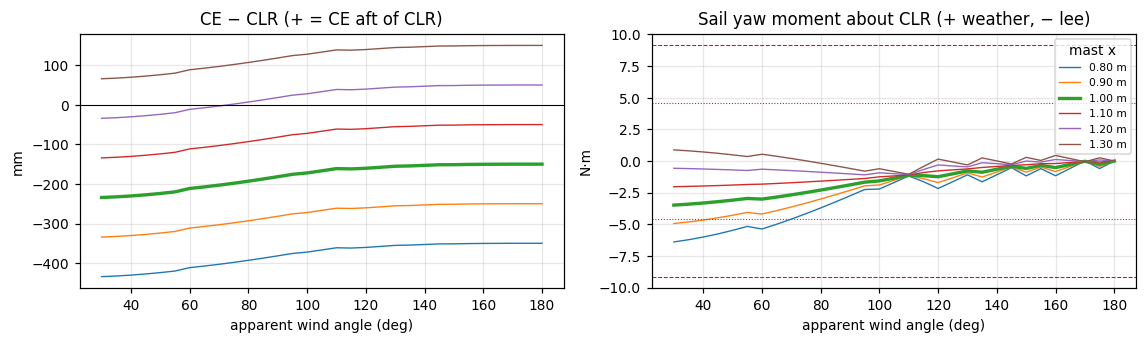

Packaging at x = 1.00 m: half-beam 0.244 m, depth 0.254 m; drive height between bushings ≈ 0.14 m (L_brg − 40 mm deck bushing − 30 mm heel bushing − 20 mm clearance) [A]


In [33]:
rows, curves = [], {}
for mx in (0.80, 0.90, 1.00, 1.10, 1.20, 1.30):
    s = HB if mx == BASE["mast_x"] else helm_sweep(mx, BASE["span"], BASE["chord"], PLATE); curves[mx] = s
    lee = max(0.0, -s[s[:, 0] >= 40, 2].min()); run = s[-1, 1]
    rows.append([f"{mx:.2f}" + (" (baseline)" if mx == BASE["mast_x"] else ""), f"{s[s[:,0]==45,1][0]*1000:+.0f}",
                 f"{run*1000:+.0f} " + ("tracks" if run < 0 else "**unstable**"), f"{lee:.1f} ({lee/M_rud*100:.0f} %)"])
table(rows, ["Mast x (m)", "CE − CLR at 45° AWA (mm)", "CE − CLR running (mm)", "Max lee helm, N·m (% of rudder)"])
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
for mx, s in curves.items():
    lw = 2.2 if mx == BASE["mast_x"] else 0.9
    ax[0].plot(s[:, 0], s[:, 1]*1000, lw=lw, label=f"{mx:.2f} m"); ax[1].plot(s[:, 0], s[:, 2], lw=lw, label=f"{mx:.2f} m")
ax[0].axhline(0, c="k", lw=.7); ax[0].set(title="CE − CLR (+ = CE aft of CLR)", xlabel="apparent wind angle (deg)", ylabel="mm")
for y in (M_rud, -M_rud): ax[1].axhline(y, c="r", ls="--", lw=.7)
for y in (M_rud/2, -M_rud/2): ax[1].axhline(y, c="r", ls=":", lw=.7)
ax[1].set(title="Sail yaw moment about CLR (+ weather, − lee)", xlabel="apparent wind angle (deg)", ylabel="N·m"); ax[1].legend(fontsize=7, title="mast x")
plt.tight_layout(); plt.show()
print(f"Packaging at x = 1.00 m: half-beam {np.interp(1.0, XS[:-1], [s['T1_y'] for s in STATIONS]):.3f} m, "
      f"depth {np.interp(1.0, XS[:-1], [s['sheer_z'] - KEEL_Z[s['x']] for s in STATIONS]):.3f} m; "
      f"drive height between bushings ≈ {Z['L_brg'] - 0.04 - 0.03 - 0.02:.2f} m (L_brg − 40 mm deck bushing − 30 mm heel bushing − 20 mm clearance) [A]")

**Result.** At 1.00 m the running CE is 150 mm ahead of the CLR, which covers the whole CLR uncertainty band. The worst lee helm is about a third of the placeholder rudder's capacity. At 1.20 m the boat is unstable downwind; further forward than 1.00 m, lee helm grows toward the rudder limit for little downwind benefit. At 1.00 m the hull is at its widest, so the motor fits beside the mast.

## 6.3 What limits sail size? (trade sweep)
Every combination of span (0.60–1.40 m), chord (0.50–0.90 m), bulb mass (5–12 kg) and bulb depth (0.22–0.46 m) is run through `size_rig`, and four margins are computed:


$$\text{margin} = \text{capacity}/\text{demand} \tag{E59}$$



| Constraint | Demand | Capacity |
|---|---|---|
| Drive | gearbox static torque (E52) | 130 N·m: **placeholder** until a gearbox is chosen (open item 1) |
| Heel | full-power wind (E35) | ≥ 12 kn |
| Self-righting | AVS (3.4) | ≥ 135°: **placeholder** |
| Mast | σ_ult (E40) | ≤ 400 MPa |

Extra ballast *adds* displacement (E33), and rig mass and CG scale with span and chord.

In [34]:
CAP = dict(drive=130.0, V_fp=12.0, AVS=135.0, sigma=400e6)
def margins(r):                                                                      # (E59)
    return dict(drive=CAP["drive"]/r["T_static"], heel=r["V_fp"]/CAP["V_fp"], avs=r["AVS"]/CAP["AVS"], mast=CAP["sigma"]/r["sigma_ult"])
SPANS  = np.round(np.arange(0.60, 1.401, 0.05), 3); CHORDS = np.round(np.arange(0.50, 0.901, 0.025), 3)
BULBS  = [5, 7, 9, 10, 12]; DEPTHS = [0.22, 0.28, 0.34, 0.40, 0.46]
SWEEP = {}
for bk in BULBS:
    for bd in DEPTHS:
        for s_ in SPANS:
            for c_ in CHORDS:
                r = size_rig(float(s_), float(c_), PLATE, bk, bd); SWEEP[(bk, bd, s_, c_)] = (r, margins(r))
print("Baseline margins: " + ", ".join(f"{k} {v:.2f}" for k, v in margins(B).items()))

Baseline margins: drive 1.38, heel 1.02, avs 0.92, mast 3.97


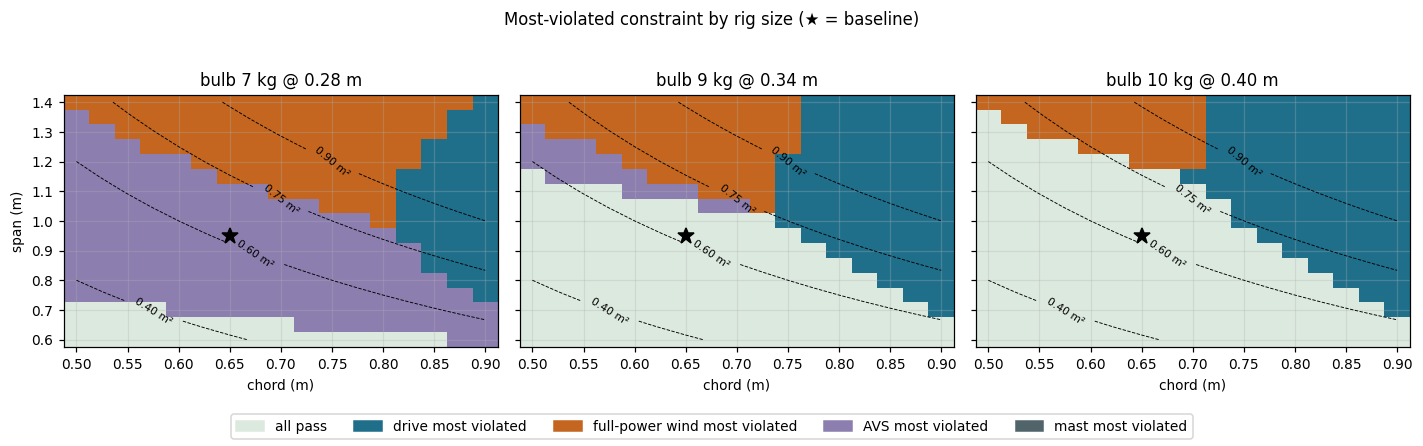

| Largest passing area, m² (span × chord) | bulb @ 0.22 m | bulb @ 0.28 m | bulb @ 0.34 m | bulb @ 0.40 m | bulb @ 0.46 m |
|---|---|---|---|---|---|
| 5 kg | none | none | 0.33 (0.60×0.550) | 0.53 (0.60×0.875) | 0.61 (0.70×0.875) |
| 7 kg | none | 0.51 (0.60×0.850) | 0.62 (0.75×0.825) | 0.70 (0.90×0.775) | 0.72 (1.00×0.725) |
| 9 kg | 0.53 (0.60×0.875) | 0.66 (0.80×0.825) | 0.72 (1.00×0.725) | 0.76 (1.05×0.725) | 0.78 (1.15×0.675) |
| 10 kg | 0.59 (0.65×0.900) | 0.70 (0.90×0.775) | 0.76 (1.05×0.725) | 0.78 (1.15×0.675) | 0.81 (1.20×0.675) |
| 12 kg | 0.68 (0.85×0.800) | 0.77 (1.10×0.700) | 0.78 (1.20×0.650) | 0.81 (1.25×0.650) | 0.85 (1.30×0.650) |

In [35]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
CATS = ["pass", "drive", "heel", "avs", "mast"]
cmap = ListedColormap(["#DCE9DF", "#1F6F8B", "#C4661F", "#8C7FB0", "#51646A"])
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (bk, bd) in zip(axs, [(7, 0.28), (9, 0.34), (10, 0.40)]):
    Zc = np.array([[0 if min(SWEEP[(bk, bd, s_, c_)][1].values()) >= 1 else CATS.index(min(SWEEP[(bk, bd, s_, c_)][1], key=SWEEP[(bk, bd, s_, c_)][1].get))
                    for c_ in CHORDS] for s_ in SPANS])
    ax.pcolormesh(CHORDS, SPANS, Zc, cmap=cmap, vmin=-0.5, vmax=4.5, shading="nearest")
    Cg, Sg = np.meshgrid(CHORDS, SPANS); cs = ax.contour(Cg, Sg, Cg*Sg, levels=[0.4, 0.6, 0.75, 0.9], colors="k", linewidths=.6, linestyles="--")
    ax.clabel(cs, fmt=lambda v: f"{v:.2f} m²", fontsize=7)
    ax.plot(BASE["chord"], BASE["span"], "k*", ms=11); ax.set(title=f"bulb {bk} kg @ {bd:.2f} m", xlabel="chord (m)")
axs[0].set_ylabel("span (m)")
fig.legend([Patch(color=cmap(i)) for i in range(5)], ["all pass", "drive most violated", "full-power wind most violated", "AVS most violated", "mast most violated"], loc="lower center", ncol=5)
fig.suptitle("Most-violated constraint by rig size (★ = baseline)"); fig.tight_layout(rect=[0, 0.08, 1, 0.95]); plt.show()
rows = []
for bk in BULBS:
    row = [f"{bk} kg"]
    for bd in DEPTHS:
        ok = [(r["A"], s_, c_) for (b, d, s_, c_), (r, m) in SWEEP.items() if b == bk and d == bd and min(m.values()) >= 1]
        row.append(f"{max(ok)[0]:.2f} ({max(ok)[1]:.2f}×{max(ok)[2]:.3f})" if ok else "none")
    rows.append(row)
table(rows, ["Largest passing area, m² (span × chord)"] + [f"bulb @ {d:.2f} m" for d in DEPTHS])

In [36]:
for lab, kw in (("+1 kg bulb", dict(bulb_kg=8.0)), ("+0.06 m bulb depth", dict(bulb_depth=0.34))):
    r = size_rig(BASE["span"], BASE["chord"], PLATE, **{**dict(bulb_kg=7.0, bulb_depth=0.28), **kw})
    print(f"{lab:20s}: full-power wind {r['V_fp']-B['V_fp']:+.2f} kn, AVS {r['AVS']-B['AVS']:+.1f}°")
r = size_rig(BASE["span"] + 0.1, BASE["chord"], PLATE); print(f"+0.1 m span          : AVS {r['AVS']-B['AVS']:+.1f}°")
for dsp in (25.0, 28.0):                       # what KG would give AVS = 180°?
    for kg in np.arange(0.0, -0.41, -0.01):
        if (gz_curve(dsp, kg)[1:-1] > 0).all(): print(f"Self-righting from inverted at {dsp:.0f} kg needs KG ≤ {kg:+.2f} m (baseline KG {B['KG']:+.2f} m)"); break

+1 kg bulb          : full-power wind +0.52 kn, AVS +4.6°
+0.06 m bulb depth  : full-power wind +0.48 kn, AVS +6.4°
+0.1 m span          : AVS -5.2°
Self-righting from inverted at 25 kg needs KG ≤ -0.22 m (baseline KG +0.01 m)
Self-righting from inverted at 28 kg needs KG ≤ -0.18 m (baseline KG +0.01 m)


**Findings** (F1, F2 in `1_Design_Decisions.md`):
1. **The drive limits chord, and heel limits span.** The mast is never close to limiting. A heavier or deeper keel moves the largest passing sail taller and narrower, but keel levers are weak (above).
2. **Full self-righting (AVS 180°) is out of reach** for any keel in this range, and sail size moves AVS only a few degrees (above). With the itemised sail mass (5.3), the baseline (★) shows AVS ~124° against the 135° placeholder with the 7 kg bulb. AVS is therefore treated as a hull and layout question, deferred, and not used to size the sail.

## 6.4 Final size and aspect ratio (D8)
Since the drive binds, the size is set by torque. Every term in (E51) is proportional to $q\,A\,c$, and at fixed aspect ratio $c = \sqrt{A/AR}$, so


$$T \propto A\,c = A^{3/2}/\sqrt{AR} \tag{E60}$$


Hold torque is steep in area (power 1.5) and weak in aspect ratio (power −0.5), while mast moment and heel grow with span.

- **Left plot:** at fixed area, raising AR buys a small torque cut at the cost of mast and heel loads.
- **Right plot:** the static requirement against area. The baseline's 94 N·m fits one common worm size (6.5); a 0.75 m² sail would need about 132 N·m, which does not.

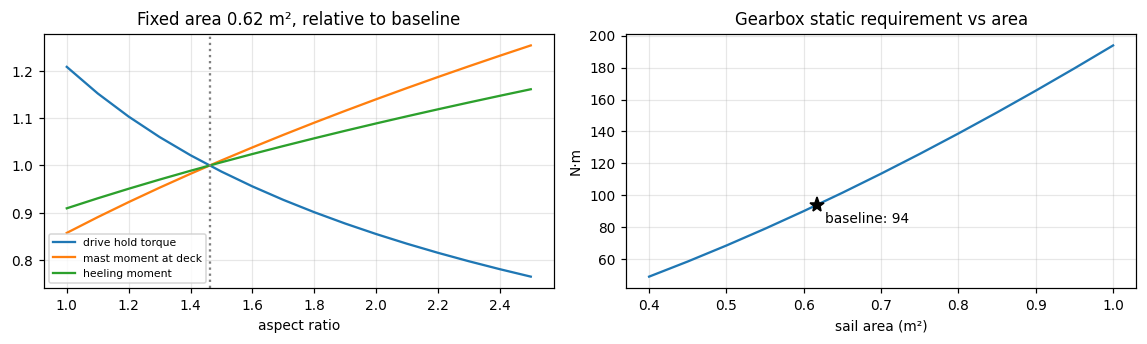

Fixed area, AR 1.5 → 2.0: T_hold -13%, M_lim +13%, h_heel +8%
Cost vs a 0.75 m² sail (1.00 × 0.75 m, static 132 N·m): force below ~11 kn is 18% lower (≈ 9% slower, taking speed ∝ √force at low speed). Above ~11–12 kn both are depowered, so there is no difference.


In [37]:
A0, AR0 = B["A"], B["AR"]
ars = np.linspace(1.0, 2.5, 16); rel = {k: [] for k in ("T_hold", "M_lim", "h_heel")}
for ar in ars:
    c_ = math.sqrt(A0/ar); r = size_rig(ar*c_, c_, PLATE)
    rel["T_hold"].append(r["T_hold"]/B["T_hold"]); rel["M_lim"].append(r["M_lim"]/B["M_lim"])
    rel["h_heel"].append(r["z_h_heel"]/B["z_h_heel"])          # heeling moment at fixed area ∝ heeling arm
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
for k, lab in (("T_hold", "drive hold torque"), ("M_lim", "mast moment at deck"), ("h_heel", "heeling moment")): ax[0].plot(ars, rel[k], label=lab)
ax[0].axvline(AR0, c="gray", ls=":"); ax[0].set(title=f"Fixed area {A0:.2f} m², relative to baseline", xlabel="aspect ratio"); ax[0].legend(fontsize=7)
areas = np.linspace(0.4, 1.0, 13)
ax[1].plot(areas, [size_rig(math.sqrt(a_*AR0), math.sqrt(a_/AR0), PLATE)["T_static"] for a_ in areas], label=f"AR {AR0:.2f}")
ax[1].plot(A0, B["T_static"], "k*", ms=10); ax[1].annotate(f"baseline: {B['T_static']:.0f}", (A0, B["T_static"]), xytext=(5, -12), textcoords="offset points")
ax[1].set(title="Gearbox static requirement vs area", xlabel="sail area (m²)", ylabel="N·m"); plt.tight_layout(); plt.show()
i15, i20 = np.argmin(abs(ars - 1.5)), np.argmin(abs(ars - 2.0))
print("Fixed area, AR 1.5 → 2.0: " + ", ".join(f"{k} {rel[k][i20]/rel[k][i15] - 1:+.0%}" for k in rel))
Big = size_rig(1.00, 0.75, PLATE)
print(f"Cost vs a 0.75 m² sail (1.00 × 0.75 m, static {Big['T_static']:.0f} N·m): force below ~11 kn is {1 - B['A']/Big['A']:.0%} lower "
      f"(≈ {1 - math.sqrt(B['A']/Big['A']):.0%} slower, taking speed ∝ √force at low speed). "
      f"Above ~{Big['V_fp']:.0f}–{B['V_fp']:.0f} kn both are depowered, so there is no difference.")

## 6.5 Drive hardware (D9)
### Gearbox against catalog data
Catalog **continuous** output ratings, 1,400 rpm input, service factor 1 [L13]. Holding is a static load, and static capacity normally exceeds the continuous rating, so treating continuous as the holding limit builds in margin. Self-locking generally needs static efficiency below 50 %, i.e. a small lead angle and a high ratio [L14]. With a final spur or chain stage $i_f$ on the mast, the worm sees


$$T_{worm} = T_{hold}/i_f \tag{E61}$$


ignoring the final stage's efficiency, which is conservative when holding.

In [38]:
CATALOG = {"NMRV030": {60: 19, 80: 14}, "NMRV040": {60: 43, 80: 34, 100: 38}, "NMRV050": {60: 89, 80: 72, 100: 60}}   # N·m continuous [L13]
rows = []
for size, ratings in CATALOG.items():
    for i, Tc in ratings.items():
        for i_f in (1, 2, 3):
            need = B["T_hold"]/i_f                                                    # (E61)
            if Tc >= need: rows.append([size, i, Tc, f"{i_f}:1", f"{need:.0f}", f"{Tc/need:.2f}"])
table(rows, ["Worm", "ratio", "continuous (N·m)", "final stage", "worm torque in hold (N·m)", "margin"])

| Worm | ratio | continuous (N·m) | final stage | worm torque in hold (N·m) | margin |
|---|---|---|---|---|---|
| NMRV040 | 60 | 43 | 2:1 | 31 | 1.37 |
| NMRV040 | 60 | 43 | 3:1 | 21 | 2.06 |
| NMRV040 | 80 | 34 | 2:1 | 31 | 1.08 |
| NMRV040 | 80 | 34 | 3:1 | 21 | 1.63 |
| NMRV040 | 100 | 38 | 2:1 | 31 | 1.21 |
| NMRV040 | 100 | 38 | 3:1 | 21 | 1.82 |
| NMRV050 | 60 | 89 | 1:1 | 63 | 1.42 |
| NMRV050 | 60 | 89 | 2:1 | 31 | 2.84 |
| NMRV050 | 60 | 89 | 3:1 | 21 | 4.26 |
| NMRV050 | 80 | 72 | 1:1 | 63 | 1.15 |
| NMRV050 | 80 | 72 | 2:1 | 31 | 2.30 |
| NMRV050 | 80 | 72 | 3:1 | 21 | 3.44 |
| NMRV050 | 100 | 60 | 2:1 | 31 | 1.91 |
| NMRV050 | 100 | 60 | 3:1 | 21 | 2.87 |

### Motor


$$P_{mech} = T_{op}\,\omega,\qquad \omega = \pi/t_{180} \tag{E62}$$
$$T_{motor} = \frac{T_{op}}{i_{tot}\,\eta} \tag{E63}$$



In [39]:
for t180, eta in ((20, 0.25), (10, 0.25), (10, eta_drive)):
    Pm = B["T_op"]*math.pi/t180; print(f"180° in {t180:>2d} s, η {eta:.2f}: P_mech {Pm:.1f} W (E62), P_el {Pm/eta:.1f} W")
i_tot = 20*50*2
print(f"Motor torque (E63) through 20:1 gearmotor × 50:1 worm × 2:1 final = {i_tot}:1 at η {eta_drive}: {B['T_op']/(i_tot*eta_drive)*1000:.0f} mN·m")
for v_last in (27, 35):
    print(f"'Last-move' wind {v_last} kn → motor-train operating torque ≈ {B['T_op']*(v_last/27)**2:.0f} N·m")

180° in 20 s, η 0.25: P_mech 2.9 W (E62), P_el 11.7 W
180° in 10 s, η 0.25: P_mech 5.9 W (E62), P_el 23.5 W
180° in 10 s, η 0.30: P_mech 5.9 W (E62), P_el 19.6 W
Motor torque (E63) through 20:1 gearmotor × 50:1 worm × 2:1 final = 2000:1 at η 0.3: 31 mN·m
'Last-move' wind 27 kn → motor-train operating torque ≈ 19 N·m
'Last-move' wind 35 kn → motor-train operating torque ≈ 31 N·m


## 6.6 Ballast the sail needs (F3)
Solve $V_{fp}(m_{bulb}) = 12$ kn (E35) at 0.28 m bulb depth by bisection. This is the minimum ballast the *sail* demands. Anything above it is for survivability and self-righting.

In [40]:
def bulb_for(V_target=12.0, depth=0.28, build=None):
    lo, hi = 1.0, 15.0
    for _ in range(40):
        mid = (lo + hi)/2
        lo, hi = (mid, hi) if size_rig(BASE["span"], BASE["chord"], PLATE, mid, depth, build)["V_fp"] < V_target else (lo, mid)
    return hi
bulb_12 = bulb_for(); r12 = size_rig(BASE["span"], BASE["chord"], PLATE, bulb_12, 0.28)
print(f"Bulb for full power to 12 kn: {bulb_12:.1f} kg @ 0.28 m  → displacement {r12['disp']:.1f} kg, ballast ratio {bulb_12/r12['disp']:.0%}")

Bulb for full power to 12 kn: 6.5 kg @ 0.28 m  → displacement 25.1 kg, ballast ratio 26%


## 6.7 Sail construction: composite sandwich vs non-composite (D10)
The question here is whether the composite layup (5.3) is worth its manufacturing effort, or whether a simpler sheet-and-rib sail would do. Five constructions are sized to the **same loads and criteria** as the baseline panel (5.8):
- **Strength:** $p_{ult}$ ≤ the ultimate allowable, $p_{lim}$ ≤ yield (metals), and $p_{op}$ ≤ the seawater fatigue allowable (every wave, ~1.6 million cycles).
- **Deflection at limit load:** ≤ W_MAX = 5 mm, and a sheet between ribs ≤ $s_r$/100, which keeps the arc shape.
- **Minimum stock gauge** for dents, handling and UV: 1.0 mm aluminium, 2.0 mm polycarbonate, 3 mm ACM [A].

| Option | Construction |
|---|---|
| A. Glass/foam sandwich (baseline) | 5.3 layup; self-supporting from the spine; no ribs |
| B. Carbon/foam sandwich | As A, with 1 × 200 g/m² carbon per face |
| C. Aluminium sheet + ribs | 5052-H32 sheet pre-rolled to R_arc; 6061-T6 4 mm flat-bar ribs, riveted/bonded |
| D. Polycarbonate sheet + ribs | UV-stabilised PC cold-bent onto the same aluminium ribs |
| E. Aluminium composite panel + ribs | 0.3 mm aluminium skins on a PE core (Dibond type), roll-bent; same ribs |

**Sheet-and-rib model.** The sheet spans spanwise between rib stations at spacing $s_r$, continuous over the ribs (a strip fixed at each rib). Its section modulus per unit width $S_s$ is $t^2/6$ for a solid sheet, or $t_f d$ for ACM, whose stiffness follows (E47). A sheet cold-bent to the arc carries a locked-in bending stress. Each half-rib is a chordwise cantilever of length $L = c/2$ carrying the pressure on its tributary width $s_r$:


$$M_s = \frac{p\,s_r^2}{12},\qquad \sigma_s = \frac{M_s}{S_s} + \sigma_{bend} \tag{E64}$$
$$D_s = \frac{E\,t^3}{12(1-\nu^2)},\qquad w_s = \frac{p\,s_r^4}{384\,D_s} \tag{E65}$$
$$\sigma_{bend} = \frac{E\,t}{2R_{arc}} \tag{E66}$$
$$M_r = \frac{p\,s_r L^2}{2},\quad \sigma_r = \frac{6M_r}{b h^2},\quad w_r = \frac{p\,s_r L^4}{8E\,(b h^3/12)} \tag{E67}$$
$$m_{sail} = 1.02A\,(m''_{sheet} + 2m''_{paint}) + n_{st}\left(2k_t\,\rho_r\,b\,h\,L + m_{hw}\right) \tag{E68}$$



For each option, the number of rib stations (3–12) is chosen for minimum mass. The sheet is the thinnest stock gauge that passes, and the rib depth $h$ is the smallest that passes, rounded up to 1 mm.

The ribs go on the **concave face**. The plate is flipped end-for-end on each tack, so the concave face is always the windward (pressure) side, and the ribs never sit in the suction-side flow.

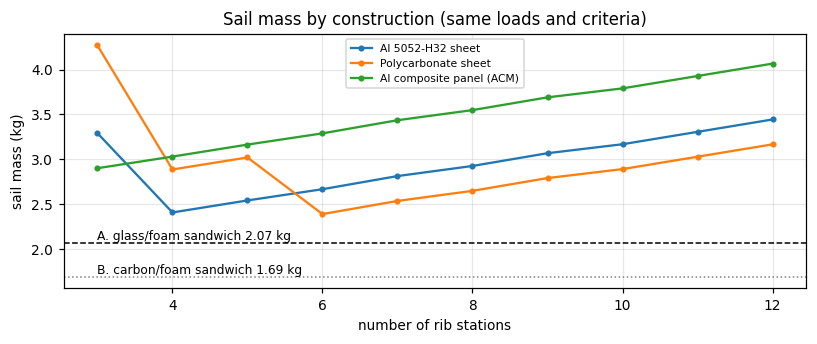

Carbon faces: t_f 0.25 mm, face stress 17 MPa, tip deflection 1.3 mm


In [41]:
def sheet_panel(mat, g):
    # Stiffness D, section modulus S (per unit width), areal mass and thickness for one stock gauge (mm).
    t = g/1000
    if "acm" in mat:
        t_f = mat["acm"]["t_f"]; tc = t - 2*t_f; d = tc + t_f
        return dict(t=t, D=mat["E"]*t_f*d**2/2, S=t_f*d, areal=2*t_f*mat["rho"] + tc*mat["acm"]["rho_core"])   # (E47)
    return dict(t=t, D=mat["E"]*t**3/(12*(1 - mat["nu"]**2)), S=t**2/6, areal=mat["rho"]*t)                     # (E65)

def sheet_gauge(mat, s_r):
    for g in mat["gauges"]:
        if g < mat["t_min"]: continue
        Pn = sheet_panel(mat, g)
        s_b = mat["E"]*Pn["t"]/(2*B["R_arc"]) if mat["coldbend"] else 0.0                   # (E66)
        sig = lambda p: p*s_r**2/12/Pn["S"]                                                  # (E64)
        w = p_lim*s_r**4/(384*Pn["D"])                                                       # (E65)
        if (sig(p_ult) + s_b <= mat["ult"] and sig(p_lim) + s_b <= mat["yld"] and sig(p_op) <= mat["fat"]
                and w <= min(W_MAX, W_SPAN*s_r)):
            return g, Pn
    return None, None

def rib_depth(s_r, L=L_h, r=RIB):
    h = [math.sqrt(6*p*s_r*L**2/2/(r["b"]*al)) for p, al in ((p_ult, r["ult"]), (p_lim, r["yld"]), (p_op, r["fat"]))]   # (E67)
    h.append((p_lim*s_r*L**4*12/(8*r["E"]*r["b"]*W_MAX))**(1/3))
    return math.ceil(max(h)*1000)/1000

def sheet_option(mat, n_st, span=BASE["span"], chord=BASE["chord"]):
    s_r = span/(n_st - 1); g, Pn = sheet_gauge(mat, s_r)
    if g is None: return None
    h = rib_depth(s_r); A = span*chord
    items = {"sheet": 1.02*A*Pn["areal"], "paint": 1.02*A*2*mat["paint"],
             "ribs": n_st*2*RIB["taper"]*RIB["rho"]*RIB["b"]*h*(chord/2), "collars + fasteners": n_st*RIB["hw"]}      # (E68)
    return dict(n_st=n_st, s_r=s_r, gauge=g, h=h, items=items, m=sum(items.values()))

SHEET_RES = {name: [r for r in (sheet_option(mat, n) for n in range(3, 13)) if r] for name, mat in SHEET.items()}
BEST = {name: min(rs, key=lambda r: r["m"]) for name, rs in SHEET_RES.items()}

CARBON = {**LAYUP, "plies": 1, "fabric": 0.200, "rho_f": 1780, "Vf": 0.45, "E_f": 50e9, "sigma_f": 200e6}   # 1 × 200 g/m² carbon twill per face [A], [L17]
Sc = sandwich_check(CARBON)
m_A = sail_mass_sandwich(BASE["span"], BASE["chord"]); m_B = sail_mass_sandwich(BASE["span"], BASE["chord"], L=CARBON)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
for name, rs in SHEET_RES.items():
    ax.plot([r["n_st"] for r in rs], [r["m"] for r in rs], "o-", ms=3, label=name)
ax.axhline(m_A, c="k", ls="--", lw=1); ax.text(3, m_A + 0.03, f"A. glass/foam sandwich {m_A:.2f} kg", fontsize=8)
ax.axhline(m_B, c="gray", ls=":", lw=1); ax.text(3, m_B + 0.03, f"B. carbon/foam sandwich {m_B:.2f} kg", fontsize=8)
ax.set(xlabel="number of rib stations", ylabel="sail mass (kg)", title="Sail mass by construction (same loads and criteria)")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"Carbon faces: t_f {Sc['t_f']*1000:.2f} mm, face stress {Sc['sigma']/1e6:.0f} MPa, tip deflection {Sc['w']*1000:.1f} mm")

In [42]:
def fixed(m): return lambda span, chord, sec=None: m          # a build that returns a fixed sail mass (baseline size only)
OPTS = [("A. Glass/foam sandwich (baseline)", "2 × 200 g/m² glass per face, 10 mm H60; no ribs", 0.0, m_A),
        ("B. Carbon/foam sandwich", "1 × 200 g/m² carbon per face, 10 mm H60; no ribs", 0.0, m_B)]
for name, r in BEST.items():
    OPTS.append((name.replace("Al 5052-H32 sheet", "C. Al 5052-H32 sheet + ribs").replace("Polycarbonate sheet", "D. Polycarbonate sheet + ribs")
                 .replace("Al composite panel (ACM)", "E. ACM panel + ribs"),
                 f"{r['gauge']:g} mm sheet; {r['n_st']} rib stations at {r['s_r']*1000:.0f} mm", r["h"], r["m"]))
rows = []
for name, desc, h, m in OPTS:
    r = size_rig(BASE["span"], BASE["chord"], PLATE, build=fixed(m))
    rows.append([name, desc, f"{h*1000:.0f} mm" if h else "none", f"{m:.2f}", f"{r['m_rig']:.2f} @ {r['z_rig']:+.2f}",
                 f"{r['V_fp']:.1f}", f"{r['AVS']:.0f}°", f"{bulb_for(build=fixed(m)):.1f}"])
table(rows, ["Option", "Structure", "Rib depth (concave face)", "Sail (kg)", "Rig kg @ m", "Full power to (kn)", "AVS", "Bulb for 12 kn (kg @ 0.28 m)"])
for name, r in BEST.items():
    print(f"{name}: " + ", ".join(f"{k} {v:.2f}" for k, v in r["items"].items()) + " kg")

| Option | Structure | Rib depth (concave face) | Sail (kg) | Rig kg @ m | Full power to (kn) | AVS | Bulb for 12 kn (kg @ 0.28 m) |
|---|---|---|---|---|---|---|---|
| A. Glass/foam sandwich (baseline) | 2 × 200 g/m² glass per face, 10 mm H60; no ribs | none | 2.07 | 3.15 @ +0.64 | 12.3 | 124° | 6.5 |
| B. Carbon/foam sandwich | 1 × 200 g/m² carbon per face, 10 mm H60; no ribs | none | 1.69 | 2.78 @ +0.63 | 12.5 | 128° | 6.0 |
| C. Al 5052-H32 sheet + ribs | 1 mm sheet; 4 rib stations at 317 mm | 13 mm | 2.41 | 3.49 @ +0.65 | 12.0 | 120° | 6.9 |
| D. Polycarbonate sheet + ribs | 2 mm sheet; 6 rib stations at 190 mm | 11 mm | 2.39 | 3.47 @ +0.65 | 12.0 | 120° | 6.9 |
| E. ACM panel + ribs | 3 mm sheet; 3 rib stations at 475 mm | 15 mm | 2.90 | 3.98 @ +0.66 | 11.7 | 114° | 7.6 |

Al 5052-H32 sheet: sheet 1.69, paint 0.10, ribs 0.22, collars + fasteners 0.40 kg
Polycarbonate sheet: sheet 1.51, paint 0.00, ribs 0.28, collars + fasteners 0.60 kg
Al composite panel (ACM): sheet 2.41, paint 0.00, ribs 0.19, collars + fasteners 0.30 kg


### Manufacturing comparison
| | A/B. Foam sandwich | C. Aluminium sheet + ribs | D. Polycarbonate + ribs | E. ACM + ribs |
|---|---|---|---|---|
| Tooling | 1.04 m-radius former, vacuum pump and bagging | Slip roll (or a shop that has one); waterjet/CNC for rib profiles | Rib profiles only: the sheet cold-bends | Roll-bender; rib profiles |
| Main steps | Cut and score core → laminate face 1 → cure → laminate face 2 → cure → edge closeouts → bond to mast, fillets, wrap plies → fair and paint | Cut rib profiles → roll sheet → drill → rivet/bond sheet to ribs → collars to mast → paint | Cut ribs → drill → bolt sheet to ribs → collars | As C, then seal the cut edges |
| Skills and facilities | Resin handling (PPE, ventilation), vacuum bagging, cure schedules | Sheet-metal and riveting | Basic shop | Basic shop |
| Parts count | 1 panel plus spine bond | Sheet, ~10–16 half-ribs, collars, ~100+ rivets | Similar to C | Similar to C |
| Surfaces | Smooth on both faces | Ribs protrude on the concave face | Same | Same |
| Main risks over 4 months | Skin–core debond, water entry at a damaged edge. Repairable with epoxy. | Fatigue cracks at rivet holes and rib roots; galvanic corrosion at dissimilar fasteners | Creep, UV crazing, stress cracking from adhesives/solvents, fatigue at bolt holes | PE core not meant for immersion; edge corrosion; skin delamination |
| Side benefit | Lightest; damage-tolerant (glass) | Tolerant of a bad layup day; easy to inspect | Transparent: less solar shading (Preesha) | Cheap, flat stock |

### Result: is the composite worth it?
**On mass alone, only marginally.** The glass/foam sandwich (A) is ~0.3 kg lighter than the best sheet-and-rib options (C and D). At this size that is worth only ~0.3 kn of full-power wind, ~4° of AVS and ~0.4 kg of ballast. Carbon faces (B) save another ~0.4 kg.

The case for the composite rests on other things:
1. **No joints in the fatigue zone.** Options C–E carry every wave load through rivet or bolt holes and rib roots, about 1.6 million cycles in seawater. That is their most likely failure mode, and it is not captured by the static and fatigue stress checks above. The sandwich has one continuous bonded joint at the spine, with large margins (5.8).
2. **Smooth on both faces.** The sheet options need 11–15 mm ribs on a plate whose whole arc is only 52 mm deep.
3. **Damage tolerance and repair.** Glass/epoxy dents and cracks locally and can be patched with epoxy. Riveted aluminium cracks progressively, and polycarbonate can craze from UV or stress.

The composite's extra effort is one former, vacuum bagging and two cure cycles, which is modest for a team with layup experience.

**Recommendation (D10):**
- Keep **A** as the baseline.
- **C (aluminium sheet on waterjet-cut ribs)** is the fallback if a layup can't be scheduled. It costs ~0.3 kg, a little heel performance and a fatigue-inspection burden.
- Consider **B (carbon faces)** only if mass aloft becomes critical, e.g. if an AVS requirement is set. Carbon trades impact tolerance for 0.4 kg.

---
# Part 7. Summary for other subsystems
Baseline values to hand to other subsystems. Each row comes from the section listed.

In [43]:
v = B
table([
 ["Area / AR / section", f"{v['A']:.2f} m² / {v['AR']:.2f} / 8 % arc, R {v['R_arc']:.2f} m", "5.1", "Luis, Sarah, Preesha"],
 ["Sail construction", f"E-glass/epoxy 2 × 200 g/m² per face on 10 mm H60 foam, sealed edges, mast bonded through; sail {v['m_sail']:.2f} kg", "5.3, 5.8, 6.7", "Sarah, team"],
 ["Tip / CE / foot / deck above WL", f"{v['z_tip']:+.2f} / {v['z_CE']:+.2f} / {v['z_foot']:+.2f} / {v['z_deck']:+.2f} m", "5.2", "Luis, Megan"],
 ["Mast axis", f"{BASE['mast_x']:.2f} m from bow, on centreline; Ø 42 mm through the flat deck", "6.2", "Ava, hull"],
 ["Sweep circle / keep-out", f"Ø {2*v['R_sweep']:.2f} m, deck x {BASE['mast_x']-v['R_sweep']:.3f}–{BASE['mast_x']+v['R_sweep']:.3f} m; nothing > 0.10 m tall inside", "5.1", "Preesha, Jonah, Nav"],
 ["Rig mass @ CG", f"{v['m_rig']:.1f} kg @ {v['z_rig']:+.2f} m", "5.3", "Luis"],
 ["RM(20°) / full power until (7 kg @ 0.28 m)", f"{v['RM20']:.1f} N·m / {v['V_fp']:.1f} kn; AVS {v['AVS']:.0f}°", "5.4", "Luis"],
 ["Ballast for full power to 12 kn", f"~{bulb_12:.1f} kg @ 0.28 m", "6.6", "Luis"],
 ["50 kn broadside force", f"{v['F_s']:.0f} N", "5.5", "Sarah, Ava"],
 ["Mast moment at deck, limit / ult", f"{v['M_lim']:.0f} / {v['M_ult']:.0f} N·m; CF 42 × 2.5 at σ_ult {v['sigma_ult']/1e6:.0f} MPa", "5.5–5.6", "Sarah, Ava"],
 [f"Bushings heel / deck (limit, spacing {v['z_L_brg']:.3f} m)", f"{v['R_heel']:.0f} / {v['R_deck']:.0f} N", "5.7", "Sarah, Ava"],
 ["Drive operating / hold / static", f"{v['T_op']:.0f} / {v['T_hold']:.0f} / ≥ {v['T_static']:.0f} N·m", "5.9", "Audrey"],
 ["Gearbox direction", "self-locking worm: NMRV050 (i 60–80) or NMRV040 + 2:1 final stage", "6.5", "Audrey"],
 ["Drive packaging", "~200 × 150 × 130 mm around the mast at x ≈ 1.00 m; ~0.14 m height between bushings", "6.2", "Ava, Joshua"],
 ["Energy", f"~{v['E']:.1f} Wh/day", "5.10", "Nav/ECE, Preesha"],
 ["Max lee helm (12 kn, placeholder rudder)", f"{lee_B:.1f} of {M_rud:.1f} N·m", "5.11", "Megan"],
], ["Quantity", "Value", "Section", "Who needs it"])

| Quantity | Value | Section | Who needs it |
|---|---|---|---|
| Area / AR / section | 0.62 m² / 1.46 / 8 % arc, R 1.04 m | 5.1 | Luis, Sarah, Preesha |
| Sail construction | E-glass/epoxy 2 × 200 g/m² per face on 10 mm H60 foam, sealed edges, mast bonded through; sail 2.07 kg | 5.3, 5.8, 6.7 | Sarah, team |
| Tip / CE / foot / deck above WL | +1.23 / +0.76 / +0.28 / +0.18 m | 5.2 | Luis, Megan |
| Mast axis | 1.00 m from bow, on centreline; Ø 42 mm through the flat deck | 6.2 | Ava, hull |
| Sweep circle / keep-out | Ø 0.65 m, deck x 0.675–1.325 m; nothing > 0.10 m tall inside | 5.1 | Preesha, Jonah, Nav |
| Rig mass @ CG | 3.2 kg @ +0.64 m | 5.3 | Luis |
| RM(20°) / full power until (7 kg @ 0.28 m) | 17.7 N·m / 12.3 kn; AVS 124° | 5.4 | Luis |
| Ballast for full power to 12 kn | ~6.5 kg @ 0.28 m | 6.6 | Luis |
| 50 kn broadside force | 338 N | 5.5 | Sarah, Ava |
| Mast moment at deck, limit / ult | 194 / 291 N·m; CF 42 × 2.5 at σ_ult 101 MPa | 5.5–5.6 | Sarah, Ava |
| Bushings heel / deck (limit, spacing 0.226 m) | 861 / 1199 N | 5.7 | Sarah, Ava |
| Drive operating / hold / static | 19 / 63 / ≥ 94 N·m | 5.9 | Audrey |
| Gearbox direction | self-locking worm: NMRV050 (i 60–80) or NMRV040 + 2:1 final stage | 6.5 | Audrey |
| Drive packaging | ~200 × 150 × 130 mm around the mast at x ≈ 1.00 m; ~0.14 m height between bushings | 6.2 | Ava, Joshua |
| Energy | ~3.4 Wh/day | 5.10 | Nav/ECE, Preesha |
| Max lee helm (12 kn, placeholder rudder) | 3.3 of 9.1 N·m | 5.11 | Megan |

---
# Appendix A. References

**Team sources**
- [M] `Box/26-27/Transatlantic Hull 26-27/Transatlantic Hull Shell.SLDPRT` (9/14, jy962), transcribed to `data/hull_stations_from_CAD.csv`
- [T] Hull review slides (Jason, Skyler): 25 kg displacement, "subject to change"
- [T] Keel (Luis): 7 kg bulb at ~0.28 m, rough
- [T] Rudder (Megan): 0.10 × 0.17 m at x ≈ 2.06 m, placeholder

**Literature**
- [L1] ISO 2533:1975 *Standard Atmosphere* (ρ = 1.225 kg/m³). ITTC Recommended Procedure 7.5-02-01-03, *Fresh Water and Seawater Properties* (1025 kg/m³).
- [L2] Beaufort scale: UK Met Office, https://weather.metoffice.gov.uk/guides/coast-and-sea/beaufort-scale ; NOAA WPC, https://www.wpc.ncep.noaa.gov/html/beaufort.shtml
- [L3] J. D. Anderson, *Fundamentals of Aerodynamics*: ch. 4 (thin-airfoil theory, cambered airfoil) and ch. 5 (finite wings). Helmbold's relation as in Anderson, *Aircraft Performance and Design*, eq. 2.18a.
- [L4] A. Bruining, *Aerodynamic characteristics of a curved plate airfoil section at Reynolds numbers 60,000 and 100,000 and angles of attack from −10 to +90 degrees*, TU Delft, 1979. https://repository.tudelft.nl/record/uuid:6b92442a-01f7-4b7c-8d53-c4f10720ff3e
- [L5] A. Pelletier & T. J. Mueller, "Low Reynolds Number Aerodynamics of Low-Aspect-Ratio, Thin/Flat/Cambered-Plate Wings," *J. Aircraft*, 2000. https://doi.org/10.2514/2.2676
- [L6] S. F. Hoerner, *Fluid-Dynamic Drag*, 1965, ch. 3 (plates normal to the flow; hollow/cup shapes)
- [L7] CFRP laminate density ~1,550–1,600 kg/m³ (e.g. ASM Handbook vol. 21, *Composites*)
- [L8] L. Larsson, R. Eliasson & M. Orych, *Principles of Yacht Design* (hydrostatics, GM/GZ, SA/D, sail-plan balance). Rudder C_L,max ≈ 0.8 for a low-AR foil below stall.
- [L9] R. C. Hibbeler, *Mechanics of Materials* (flexure formula, cantilever deflection)
- [L10] J. R. Morison et al., "The force exerted by surface waves on piles," *Petroleum Transactions AIME*, 1950
- [L11] Oshen C-Star PC13 MicroTransat crossing, 7 May – 13 Sep 2026, 127 days, 2,926 nmi. Yacht.de, https://www.yacht.de/en/yachts/small-cruiser/microtransat-challenge-c-star-pc13-became-the-first-autonomous-robotic-boat-to-cross-the-atlantic/ ; Smart Maritime Network, https://smartmaritimenetwork.com/2026/09/16/oshen-autonomous-vessel-completes-first-unaided-atlantic-crossing/
- [L12] Diab, *Divinycell H* technical data (H60: 60 kg/m³, shear strength 0.7 MPa, shear modulus 22 MPa). https://www-eng.lbl.gov/~ecanderssen/Composite_Design/Divynicell/H_DS.pdf
- [L13] Worm gearbox catalogs: Finer PT worm gearbox catalogue (finerpt.com); StepperOnline NMRV40 (omc-stepperonline.com); RS Components, Motovario NMRV040 100:1 (rs-online.com)
- [L14] "Self-locking in worm gears," Motion Control Tips, https://www.motioncontroltips.com/when-are-worm-gears-self-locking-and-where-is-this-useful/
- [L15] D. Zenkert, *An Introduction to Sandwich Construction*, EMAS, 1995 (thin-face sandwich stiffness, face stress, core shear, shear deflection)
- [L16] Aluminum 5052-H32 fact sheet (E 70.3 GPa, yield 193 MPa, UTS 228 MPa, fatigue 117 MPa at 5×10⁸ reversed cycles). https://www.mwcomponents.com/uploads/Resource-Center/Elgin-Material-Sheets/Aluminum-5052-H32-Fact-Sheet_Elgin.pdf
- [L17] SP Systems (Gurit), *Guide to Composites* (fibre densities; fibre volume fraction by process). https://composites.ugent.be/home_made_composites/documentation/SP_Composites_Guide.pdf

---
# Appendix B. Assumptions register
Ranked by how much each could move the design. The drive is the binding constraint, so assumptions that feed the hold torque come first.

| # | Assumption | Value used | Where | If it is wrong | How to verify |
|---|---|---|---|---|---|
| 1 | Plate moment about mid-chord (C_m0, x_cp) | −0.25, 30 % chord | 4.2, 5.9 | Hold torque scales directly. +30 % → static ~120 N·m. | 2D/3D CFD, then a bench test of a half-scale plate on a torque cell |
| 2 | Torque terms added as magnitudes (E51) | conservative | 5.9 | Real hold likely lower | Same test |
| 3 | C_F,max and C_F,broad | 1.3 / 1.35 | 4.2 | Heel, mast and bearing loads scale directly | Same test, or digitised [L4] data |
| 4 | CLR position | 1.15 m, 0.15 m deep | 1.4, 5.11 | Shifts the downwind margin mm-for-mm | Keel CAD (Luis) |
| 5 | Rudder size and boat speed | 0.017 m², 1.2 m/s | 1.4 | Changes the lee-helm % | Rudder CAD (Megan) |
| 6 | C_L/C_D tables, 0–90° | 4.3 | 4.3, 5.11 | Changes trim and helm curves | CFD sweep |
| 7 | Sail construction items: bond 0.10 and paint 0.08 kg/m² per face, edges 0.06 kg/m, spine plies and fillets | 1.5 | 5.3 | Sail mass ±0.3 kg, rig CG | Build and weigh a 300 × 300 mm panel and a 200 mm length of spine |
| 7a | Glass laminate V_f, E_f, face allowable | 0.40, 17 GPa, 100 MPa | 1.5, 5.8 | Large margins; low risk | Coupon tests |
| 7b | Deflection limits | 5 mm, s_r/100 | 5.8, 6.7 | Sets core thickness and sheet gauges | Check the shape change against aero sensitivity |
| 7c | Non-composite allowables and minimum gauges (PC 20 MPa long-term; Al fatigue ~½ of air values) | 1.5 | 6.7 | Reorders options C–E | Supplier data; fatigue coupons |
| 7d | Foil shell mass (same laminate + 25 % ribs, no foam fill) | E30 | 6.1 | Foil comparison only | Detailed foil design, if pursued |
| 8 | CF tube E and allowable | 100 GPa, 400 MPa | 5.6 | Large margin; low risk | Vendor datasheet |
| 9 | Mass of hull + systems and its CG | 15.39 kg @ +0.02 m | 1.4 | Stability, draft, freeboard | Updated mass budget; hull CAD newer than 9/14 |
| 10 | Wave-dunk case | 20 % of sail, 1.5 m/s, C_D 1.2 | 5.5 | Mast design moment if it exceeds broadside | Literature on breaking-wave loads |
| 11 | Drive and AVS capacities in the sweep | 130 N·m, 135° | 6.3 | Moves the passing region | Gearbox choice (Audrey); AVS target (team) |
| 12 | Operations profile (trims, tacks, slew, η, standby) | 1.6 | 5.10 | Energy only; not a driver | Controls team |
| 13 | Freeboard/draft fixed at the 25 kg values | — | 5.2 | < 1 mm | — |